# Insurance Claim Prediction

## Running this notebook locally

Place an authorized copy of the dataset at `data/train.csv` before running the notebook. Keep private or licensed data out of the public repository; the `data/` directory should remain local and be excluded by `.gitignore`.

Existing safe charts, aggregate outputs, and evaluation results are retained to avoid requiring a full rerun just to view the notebook. They reflect the original run and may differ when using another dataset or environment.


## Business Problem


### Problem Statement



Insurance companies aim to identify customers who are likely to claim an insurance product so that they can focus their marketing efforts on the right audience.

The objective of this project is to develop a machine learning classification model that predicts whether a customer will purchase the insurance product based on the available customer attributes.

The developed model will help the insurance marketing team improve customer targeting, optimize marketing campaigns, and increase the overall conversion rate.

### Business Objective



The primary objective of this project is to build a machine learning model that can predict whether a customer is likely to claim an insurance product.

The developed model can help the insurance marketing team:

- Identify potential customers who are more likely to claim the insurance product.
- Improve the effectiveness of marketing campaigns through targeted customer selection.
- Reduce marketing costs by focusing promotional efforts on high-potential customers.
- Support data-driven decision-making to improve customer acquisition and business growth.

## Project Workflow

## Business Problem

**Problem Statement**

**Business Objective**

---

## Dataset Understanding

**Dataset Overview**

**Data Dictionary**

**Data Types**

**Missing Values**


---

## Exploratory Data Analysis (EDA)
**Target Variable Distribution**

**Univariate Analysis**

**Correlation Analysis**

**Relationship Between `-1` Values and the Target Variable**

---

## Data Preprocessing

**Handling Missing Values**

**Encoding Strategy**

**Feature Selection (`id` Removal)**

**Train-Test Split**

---

## Model Development

### Baseline Models

- Model Comparison
- Observation

### Handling Class Imbalance (SMOTE)

- Model Comparison
- Observation

### Hyperparameter Tuning

- RandomizedSearchCV
- Observation

### Data Leakage Analysis

- Problem
- Solution

### Pipeline-Based Training

- Model Comparison
- Observation

### Threshold Optimization

- Observation

### Feature Importance Analysis

- Observation

### Feature Selection

- Observation

---

## Final Results

**Final Model**

**Business Conclusion**

**Future Improvements**

## Import Libraries

In [4]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore Warnings
import warnings
warnings.filterwarnings("ignore")

# Display Settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

##  Load the Dataset

In [5]:
from pathlib import Path
DATA_PATH = Path("data/train.csv")
df = pd.read_csv(DATA_PATH)

##  Display First Five Rows

In [ ]:
df.head()

##  Display Last Five Rows

In [ ]:
df.tail()

##  Dataset Shape

In [8]:
df.shape

(595212, 59)

In [9]:
print(f"Number of Rows    : {df.shape[0]}")
print(f"Number of Columns : {df.shape[1]}")

Number of Rows    : 595212
Number of Columns : 59


### Observation

- The dataset contains **595,212 observations** and **59 columns**, indicating a large-scale dataset suitable for building a robust machine learning model.
- The dataset consists of one target variable, one identifier column (`id`), and the remaining columns represent customer-related features used for prediction.
- The large number of observations provides sufficient data for training and evaluating multiple machine learning models.

## Dataset Columns

In [10]:
print(f"Total Columns: {len(df.columns)}")
print("\nColumn Names:")
for col in df.columns:
    print(col)

Total Columns: 59

Column Names:
id
target
ps_ind_01
ps_ind_02_cat
ps_ind_03
ps_ind_04_cat
ps_ind_05_cat
ps_ind_06_bin
ps_ind_07_bin
ps_ind_08_bin
ps_ind_09_bin
ps_ind_10_bin
ps_ind_11_bin
ps_ind_12_bin
ps_ind_13_bin
ps_ind_14
ps_ind_15
ps_ind_16_bin
ps_ind_17_bin
ps_ind_18_bin
ps_reg_01
ps_reg_02
ps_reg_03
ps_car_01_cat
ps_car_02_cat
ps_car_03_cat
ps_car_04_cat
ps_car_05_cat
ps_car_06_cat
ps_car_07_cat
ps_car_08_cat
ps_car_09_cat
ps_car_10_cat
ps_car_11_cat
ps_car_11
ps_car_12
ps_car_13
ps_car_14
ps_car_15
ps_calc_01
ps_calc_02
ps_calc_03
ps_calc_04
ps_calc_05
ps_calc_06
ps_calc_07
ps_calc_08
ps_calc_09
ps_calc_10
ps_calc_11
ps_calc_12
ps_calc_13
ps_calc_14
ps_calc_15_bin
ps_calc_16_bin
ps_calc_17_bin
ps_calc_18_bin
ps_calc_19_bin
ps_calc_20_bin


### Observation

- The dataset contains **59 columns**, including one identifier column (`id`), one target column (`target`), and **57 predictor features**.
- The predictor features are organized into four major groups based on their prefixes:
  - **`ps_ind_*`** – Individual/customer-related features.
  - **`ps_reg_*`** – Registration-related features.
  - **`ps_car_*`** – Vehicle-related features.
  - **`ps_calc_*`** – Calculated or derived features.
- Feature names ending with **`_bin`** represent binary variables, while those ending with **`_cat`** represent categorical variables. The remaining features are continuous numerical variables.
- The structured naming convention helps categorize the features and determine appropriate preprocessing techniques, feature engineering, and model development strategies in later stages of the project.

##  Dataset Information

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 595212 entries, 0 to 595211
Data columns (total 59 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              595212 non-null  int64  
 1   target          595212 non-null  int64  
 2   ps_ind_01       595212 non-null  int64  
 3   ps_ind_02_cat   595212 non-null  int64  
 4   ps_ind_03       595212 non-null  int64  
 5   ps_ind_04_cat   595212 non-null  int64  
 6   ps_ind_05_cat   595212 non-null  int64  
 7   ps_ind_06_bin   595212 non-null  int64  
 8   ps_ind_07_bin   595212 non-null  int64  
 9   ps_ind_08_bin   595212 non-null  int64  
 10  ps_ind_09_bin   595212 non-null  int64  
 11  ps_ind_10_bin   595212 non-null  int64  
 12  ps_ind_11_bin   595212 non-null  int64  
 13  ps_ind_12_bin   595212 non-null  int64  
 14  ps_ind_13_bin   595212 non-null  int64  
 15  ps_ind_14       595212 non-null  int64  
 16  ps_ind_15       595212 non-null  int64  
 17  ps_ind_16_

### Observation

- The dataset contains **59 columns**, comprising **49 integer (`int64`) features** and **10 floating-point (`float64`) features**.
- The `id` column uniquely identifies each customer record and is not expected to contribute to prediction.
- The `target` column is the dependent variable representing whether a customer purchases the insurance product.
- All columns contain **595,212 non-null values**, indicating that there are **no missing values** in the dataset.
- The dataset occupies approximately **267.9 MB** of memory, making it a moderately large dataset that requires efficient preprocessing and model training techniques.

##  Feature Categories

###   Categories

In [ ]:
# Identify different feature types based on column names

binary_features = [col for col in df.columns if "_bin" in col]
categorical_features = [col for col in df.columns if "_cat" in col]
FDS
continuous_features = [
    col for col in df.columns
    if col not in binary_features
    and col not in categorical_features
    and col not in ["id", "target"]
]

print(f"ID Column                 : 1")
print(f"Target Column             : 1")
print(f"Binary Features           : {len(binary_features)}")
print(f"Categorical Features      : {len(categorical_features)}")
print(f"Continuous Features       : {len(continuous_features)}")

ID Column                 : 1
Target Column             : 1
Binary Features           : 17
Categorical Features      : 14
Continuous Features       : 26


In [13]:
print("Binary Features:")
print(binary_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nContinuous Features:")
print(continuous_features)

Binary Features:
['ps_ind_06_bin', 'ps_ind_07_bin', 'ps_ind_08_bin', 'ps_ind_09_bin', 'ps_ind_10_bin', 'ps_ind_11_bin', 'ps_ind_12_bin', 'ps_ind_13_bin', 'ps_ind_16_bin', 'ps_ind_17_bin', 'ps_ind_18_bin', 'ps_calc_15_bin', 'ps_calc_16_bin', 'ps_calc_17_bin', 'ps_calc_18_bin', 'ps_calc_19_bin', 'ps_calc_20_bin']

Categorical Features:
['ps_ind_02_cat', 'ps_ind_04_cat', 'ps_ind_05_cat', 'ps_car_01_cat', 'ps_car_02_cat', 'ps_car_03_cat', 'ps_car_04_cat', 'ps_car_05_cat', 'ps_car_06_cat', 'ps_car_07_cat', 'ps_car_08_cat', 'ps_car_09_cat', 'ps_car_10_cat', 'ps_car_11_cat']

Continuous Features:
['ps_ind_01', 'ps_ind_03', 'ps_ind_14', 'ps_ind_15', 'ps_reg_01', 'ps_reg_02', 'ps_reg_03', 'ps_car_11', 'ps_car_12', 'ps_car_13', 'ps_car_14', 'ps_car_15', 'ps_calc_01', 'ps_calc_02', 'ps_calc_03', 'ps_calc_04', 'ps_calc_05', 'ps_calc_06', 'ps_calc_07', 'ps_calc_08', 'ps_calc_09', 'ps_calc_10', 'ps_calc_11', 'ps_calc_12', 'ps_calc_13', 'ps_calc_14']


### Observation

- The dataset consists of **59 columns**, including **1 identifier column (`id`)**, **1 target column (`target`)**, and **57 predictor features**.
- Among the predictor features, there are **17 binary features**, **14 categorical features**, and **26 continuous numerical features**.
- The presence of different feature types indicates that the dataset contains a combination of binary indicators, categorical variables, and continuous measurements, each of which may require different preprocessing techniques.
- Binary features are already encoded as 0 and 1, while categorical features are represented using integer labels. Continuous features consist of both integer and floating-point values.
- Understanding the feature categories will help determine the appropriate preprocessing strategy, feature scaling requirements, and model selection in the subsequent stages of the project.

In [ ]:
df[categorical_features].head()

In [15]:
df[categorical_features].nunique()

ps_ind_02_cat      5
ps_ind_04_cat      3
ps_ind_05_cat      8
ps_car_01_cat     13
ps_car_02_cat      3
ps_car_03_cat      3
ps_car_04_cat     10
ps_car_05_cat      3
ps_car_06_cat     18
ps_car_07_cat      3
ps_car_08_cat      2
ps_car_09_cat      6
ps_car_10_cat      3
ps_car_11_cat    104
dtype: int64

##  Missing Values

In [16]:
missing_values = df.isnull().sum()

In [17]:
missing_values[missing_values > 0]

Series([], dtype: int64)

In [18]:
print(f"Total Missing Values : {df.isnull().sum().sum()}")

Total Missing Values : 0


## Duplicate Records

In [19]:
duplicate_count = df.duplicated().sum()

In [20]:
print(f"Number of Duplicated rows :{duplicate_count}")

Number of Duplicated rows :0


## Hidden Missing Values (-1)

In [21]:
hidden_missing = (df == -1).sum()

hidden_missing = hidden_missing[hidden_missing>0]

hidden_missing.sort_values(ascending=False)

ps_car_03_cat    411231
ps_car_05_cat    266551
ps_reg_03        107772
ps_car_14         42620
ps_car_07_cat     11489
ps_ind_05_cat      5809
ps_car_09_cat       569
ps_ind_02_cat       216
ps_car_01_cat       107
ps_ind_04_cat        83
ps_car_02_cat         5
ps_car_11             5
ps_car_12             1
dtype: int64

In [22]:
print(f"Total '-1' Values in Dataset: {(df == -1).sum().sum()}")

Total '-1' Values in Dataset: 846458


### Observation

- No missing (`NaN`) values were found in the dataset, and no duplicate records were identified.
- However, the dataset contains **846,458 occurrences of `-1`**, indicating the presence of hidden missing values.
- These hidden missing values are present in both **categorical** and **continuous** features, with the highest occurrences observed in `ps_car_03_cat` and `ps_car_05_cat`.
- Since the `-1` values are distributed across different feature types, a single imputation strategy may not be appropriate. The handling of these values will be determined during the preprocessing stage based on the nature of each feature.

 ## Exploratory Data Analysis (EDA)

## Target Variable Distribution

In [23]:
df["target"].value_counts()

target
0    573518
1     21694
Name: count, dtype: int64

In [24]:
df["target"].value_counts(normalize=True)*100

target
0    96.355248
1     3.644752
Name: proportion, dtype: float64

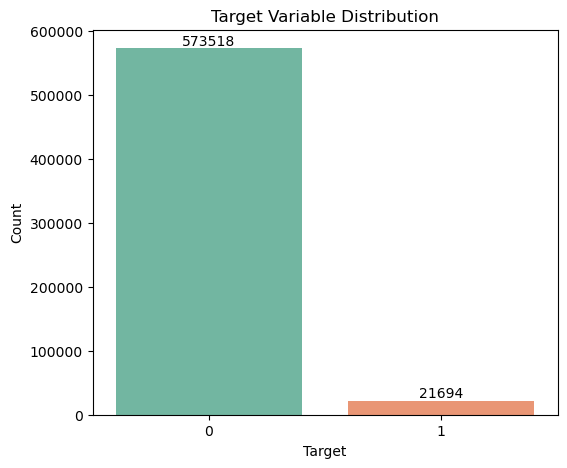

In [25]:
plt.figure(figsize=(6,5))

ax = sns.countplot(
    x="target",
    data=df,
    palette="Set2"
)

# Add count labels
for container in ax.containers:
    ax.bar_label(container)

plt.title("Target Variable Distribution")
plt.xlabel("Target")
plt.ylabel("Count")
plt.show()

### Observation

- The target variable is **highly imbalanced**, with **573,518 (96.36%)** observations belonging to Class **0** and only **21,694 (3.64%)** observations belonging to Class **1**.
- The large difference between the majority and minority classes indicates a severe class imbalance problem.
- Due to this imbalance, **Accuracy alone will not be a reliable performance metric**, as a model predicting only the majority class could still achieve high accuracy.
- Therefore, additional evaluation metrics such as **Precision, Recall, F1-score, ROC-AUC, and Precision-Recall Curve** will be considered during model evaluation.
- The impact of class imbalance will be further investigated after training the baseline models, and techniques such as **SMOTE** or **class weighting** will be considered if necessary.

## Summary Statistics

In [26]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,595212.0,743803.558435,429367.820429,7.000000,371991.500000,743547.500000,1.115549e+06,1.488027e+06
target,595212.0,0.036448,0.187401,0.000000,0.000000,0.000000,0.000000e+00,1.000000e+00
ps_ind_01,595212.0,1.900378,1.983789,0.000000,0.000000,1.000000,3.000000e+00,7.000000e+00
ps_ind_02_cat,595212.0,1.358943,0.664594,-1.000000,1.000000,1.000000,2.000000e+00,4.000000e+00
ps_ind_03,595212.0,4.423318,2.699902,0.000000,2.000000,4.000000,6.000000e+00,1.100000e+01
ps_ind_04_cat,595212.0,0.416794,0.493311,-1.000000,0.000000,0.000000,1.000000e+00,1.000000e+00
ps_ind_05_cat,595212.0,0.405188,1.350642,-1.000000,0.000000,0.000000,0.000000e+00,6.000000e+00
ps_ind_06_bin,595212.0,0.393742,0.488579,0.000000,0.000000,0.000000,1.000000e+00,1.000000e+00
ps_ind_07_bin,595212.0,0.257033,0.436998,0.000000,0.000000,0.000000,1.000000e+00,1.000000e+00
ps_ind_08_bin,595212.0,0.163921,0.370205,0.000000,0.000000,0.000000,0.000000e+00,1.000000e+00


### Observation

- The summary statistics provide an overview of the distribution and range of the numerical features.
- Most binary features contain values between **0 and 1**, confirming that they are correctly encoded.
- Several categorical and continuous features have a minimum value of **-1**, supporting the earlier observation that `-1` is used as a placeholder for hidden missing values.
- Continuous features exhibit different numerical ranges, indicating that feature scaling may be required for distance-based algorithms such as Logistic Regression and SVM.
- No abnormal maximum values or unrealistic ranges were observed in the displayed features.

## Skewness Analysis

In [27]:
# calculate skewness of continuous features

skewness = df[continuous_features].skew().sort_values(ascending=False)

skewness_df = pd.DataFrame({
    "Feature": skewness.index,
    "Skewness": skewness.values
})


skewness_df

,Feature,Skewness
0,ps_ind_14,12.207636
1,ps_car_13,1.700536
2,ps_reg_02,1.281065
3,ps_car_12,1.067176
4,ps_ind_01,0.931680
5,ps_calc_12,0.835730
6,ps_calc_13,0.587317
7,ps_ind_03,0.463530
8,ps_calc_11,0.430627
9,ps_calc_14,0.365033


In [28]:
def skew_category(x):
    if x > 1:
        return "Highly Right Skewed"
    elif x > 0.5:
        return "Moderately Right Skewed"
    elif x < -1:
        return "Highly Left Skewed"
    elif x < -0.5:
        return "Moderately Left Skewed"
    else:
        return "Approximately Symmetric"

skewness_df["Category"] = skewness_df["Skewness"].apply(skew_category)

skewness_df

,Feature,Skewness,Category
0,ps_ind_14,12.207636,Highly Right Skewed
1,ps_car_13,1.700536,Highly Right Skewed
2,ps_reg_02,1.281065,Highly Right Skewed
3,ps_car_12,1.067176,Highly Right Skewed
4,ps_ind_01,0.931680,Moderately Right Skewed
5,ps_calc_12,0.835730,Moderately Right Skewed
6,ps_calc_13,0.587317,Moderately Right Skewed
7,ps_ind_03,0.463530,Approximately Symmetric
8,ps_calc_11,0.430627,Approximately Symmetric
9,ps_calc_14,0.365033,Approximately Symmetric


In [29]:
skewness_df["Category"].value_counts()

Category
Approximately Symmetric    14
Highly Right Skewed         4
Highly Left Skewed          4
Moderately Right Skewed     3
Moderately Left Skewed      1
Name: count, dtype: int64

### Observation

- The skewness analysis shows that the continuous features exhibit varying distribution patterns.
- Out of **26 continuous features**, **14 features are approximately symmetric**, indicating that a majority of the variables follow a reasonably balanced distribution.
- **4 features are highly right-skewed** (`ps_ind_14`, `ps_car_13`, `ps_reg_02`, and `ps_car_12`), suggesting the presence of long right tails and potentially a few unusually large values.
- **3 features are moderately right-skewed**, while **4 features are highly left-skewed** and **1 feature is moderately left-skewed**, indicating that skewness exists in both directions across the dataset.
- Since the project will utilize both **linear models** (e.g., Logistic Regression and SVM) and **tree-based models** (e.g., Decision Tree, Random Forest, XGBoost), the impact of skewness will be evaluated through model performance rather than applying transformations at this stage.

## Distribution Analysis

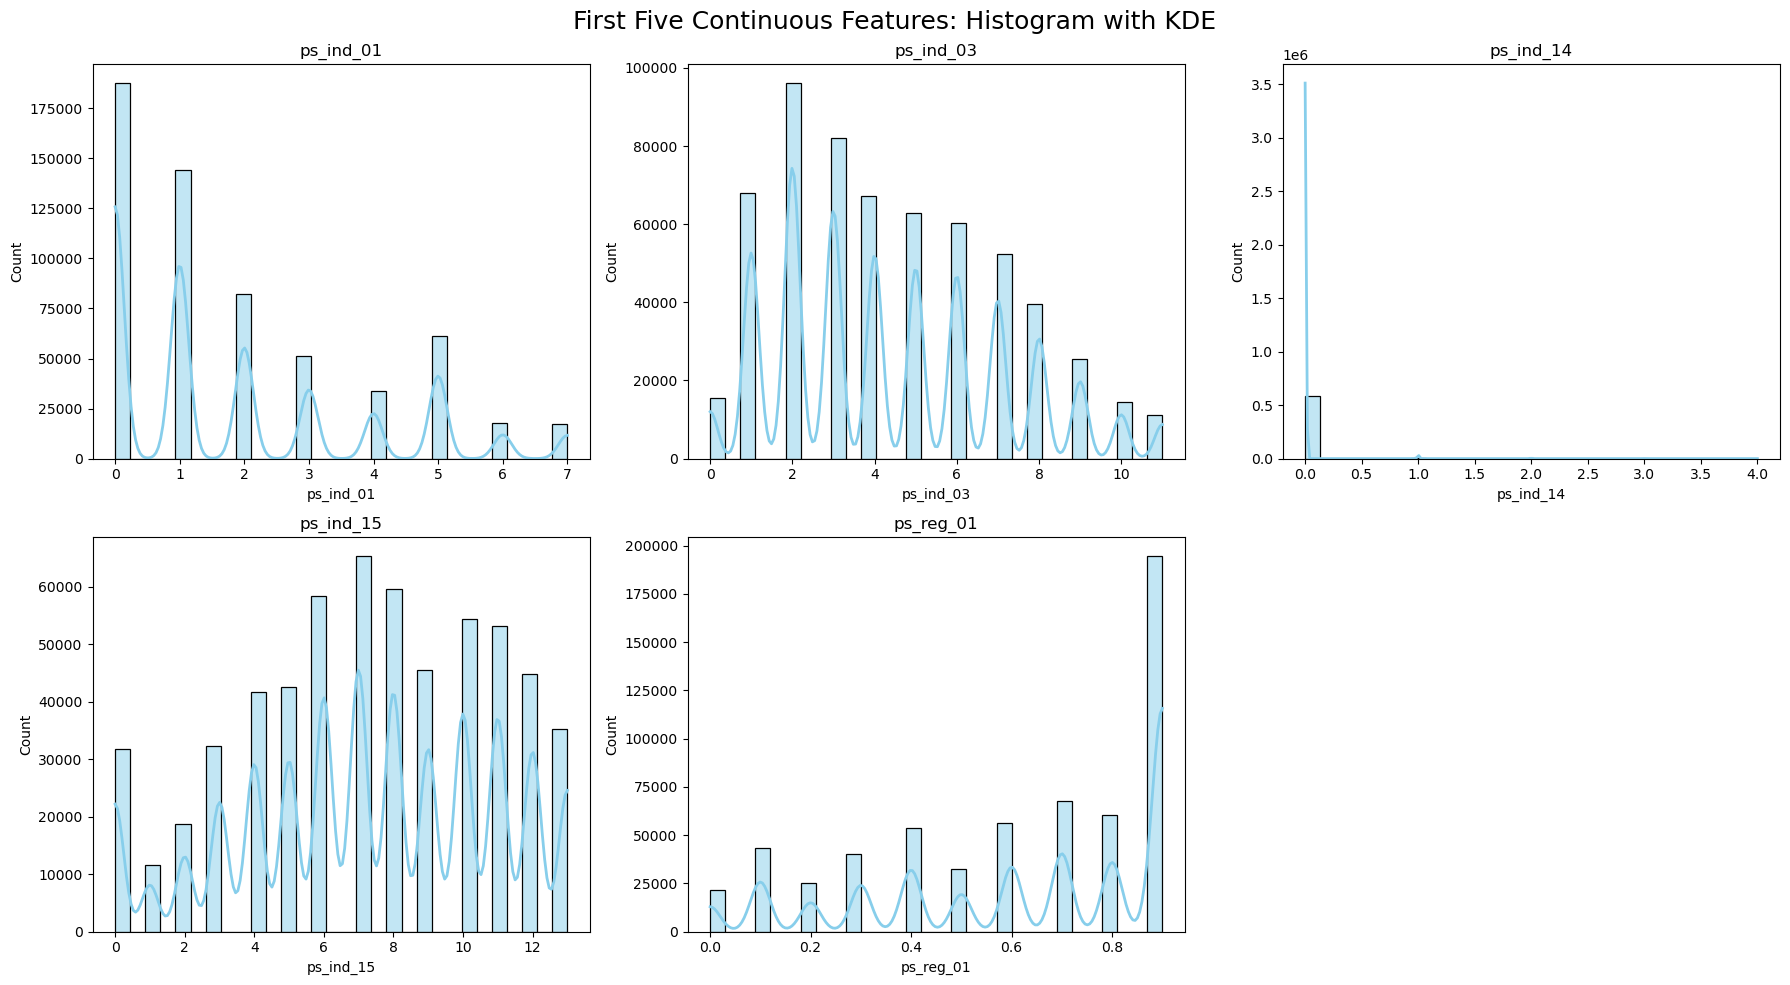

In [30]:
first_five = continuous_features[:5]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, feature in enumerate(first_five):
    sns.histplot(
        data=df,
        x=feature,
        bins=30,
        kde=True,
        color="skyblue",
        edgecolor="black",
        line_kws={"color": "red", "linewidth": 2},
        ax=axes[i]
    )

    axes[i].set_title(feature)

# Remove the unused subplot
fig.delaxes(axes[-1])

plt.suptitle("First Five Continuous Features: Histogram with KDE", fontsize=18)
plt.tight_layout()
plt.show()


### Observation

- The first five continuous features exhibit diverse distribution patterns rather than following a common distribution.
- Features such as **`ps_ind_01`**, **`ps_ind_03`**, and **`ps_ind_15`** contain discrete integer values, resulting in multiple distinct peaks instead of smooth continuous distributions.
- **`ps_reg_01`** shows values concentrated toward the higher end of its range, indicating a negatively skewed distribution.
- **`ps_ind_14`** is highly concentrated at zero with only a few observations taking larger values, confirming the strong right skew observed in the skewness analysis.
- Overall, these features are not normally distributed, suggesting that the dataset contains a mixture of discrete numerical and continuous variables.

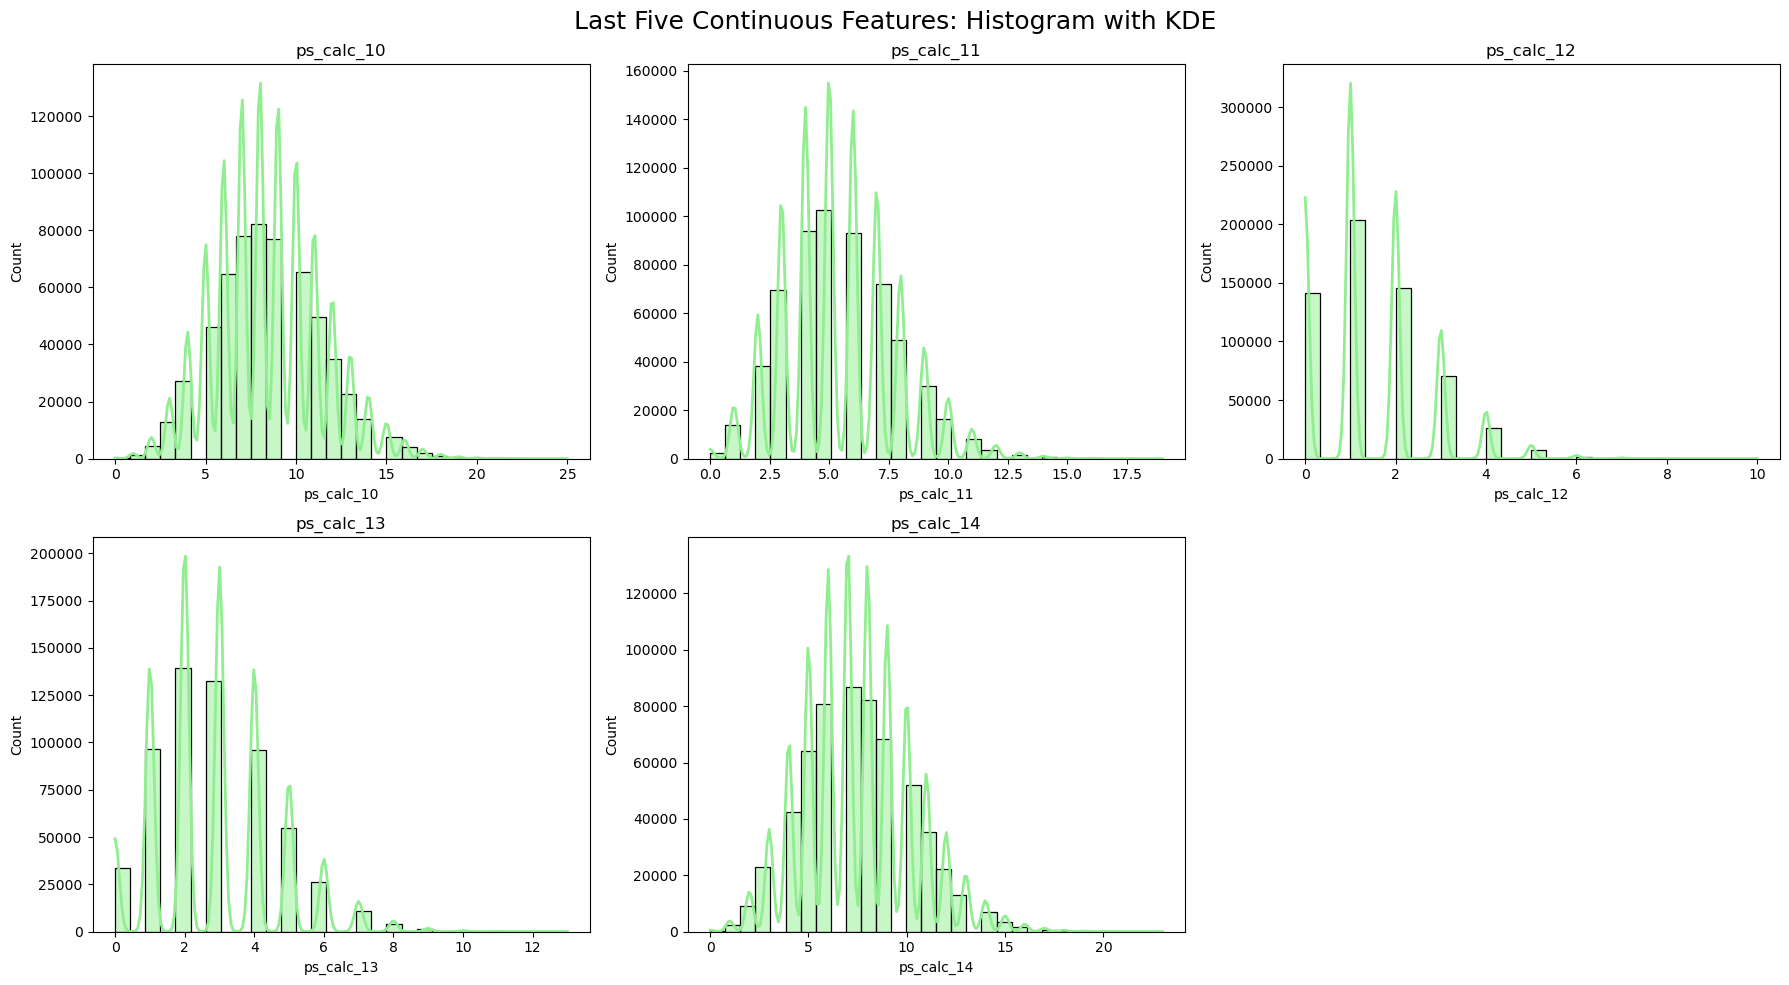

In [31]:
last_five = continuous_features[-5:]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, feature in enumerate(last_five):
    sns.histplot(
        data=df,
        x=feature,
        bins=30,
        kde=True,
        color="lightgreen",
        edgecolor="black",
        line_kws={"color": "blue", "linewidth": 2},
        ax=axes[i]
    )

    axes[i].set_title(feature)

fig.delaxes(axes[-1])

plt.suptitle("Last Five Continuous Features: Histogram with KDE", fontsize=18)
plt.tight_layout()
plt.show()

### Observation

- The last five continuous features (`ps_calc_10` to `ps_calc_14`) exhibit relatively smoother distributions compared to the earlier continuous features.
- Most variables display bell-shaped distributions with moderate skewness, although several features remain discrete due to limited integer values.
- Features such as **`ps_calc_12`** and **`ps_calc_13`** are concentrated around lower values with decreasing frequencies toward higher values, indicating right-skewed behavior.
- **`ps_calc_10`**, **`ps_calc_11`**, and **`ps_calc_14`** show distributions closer to symmetric with slight skewness and no obvious extreme irregularities.
- Overall, the calculated features appear more stable and less variable than several of the individual and registration-related features.

## Outlier Detection using Boxplots

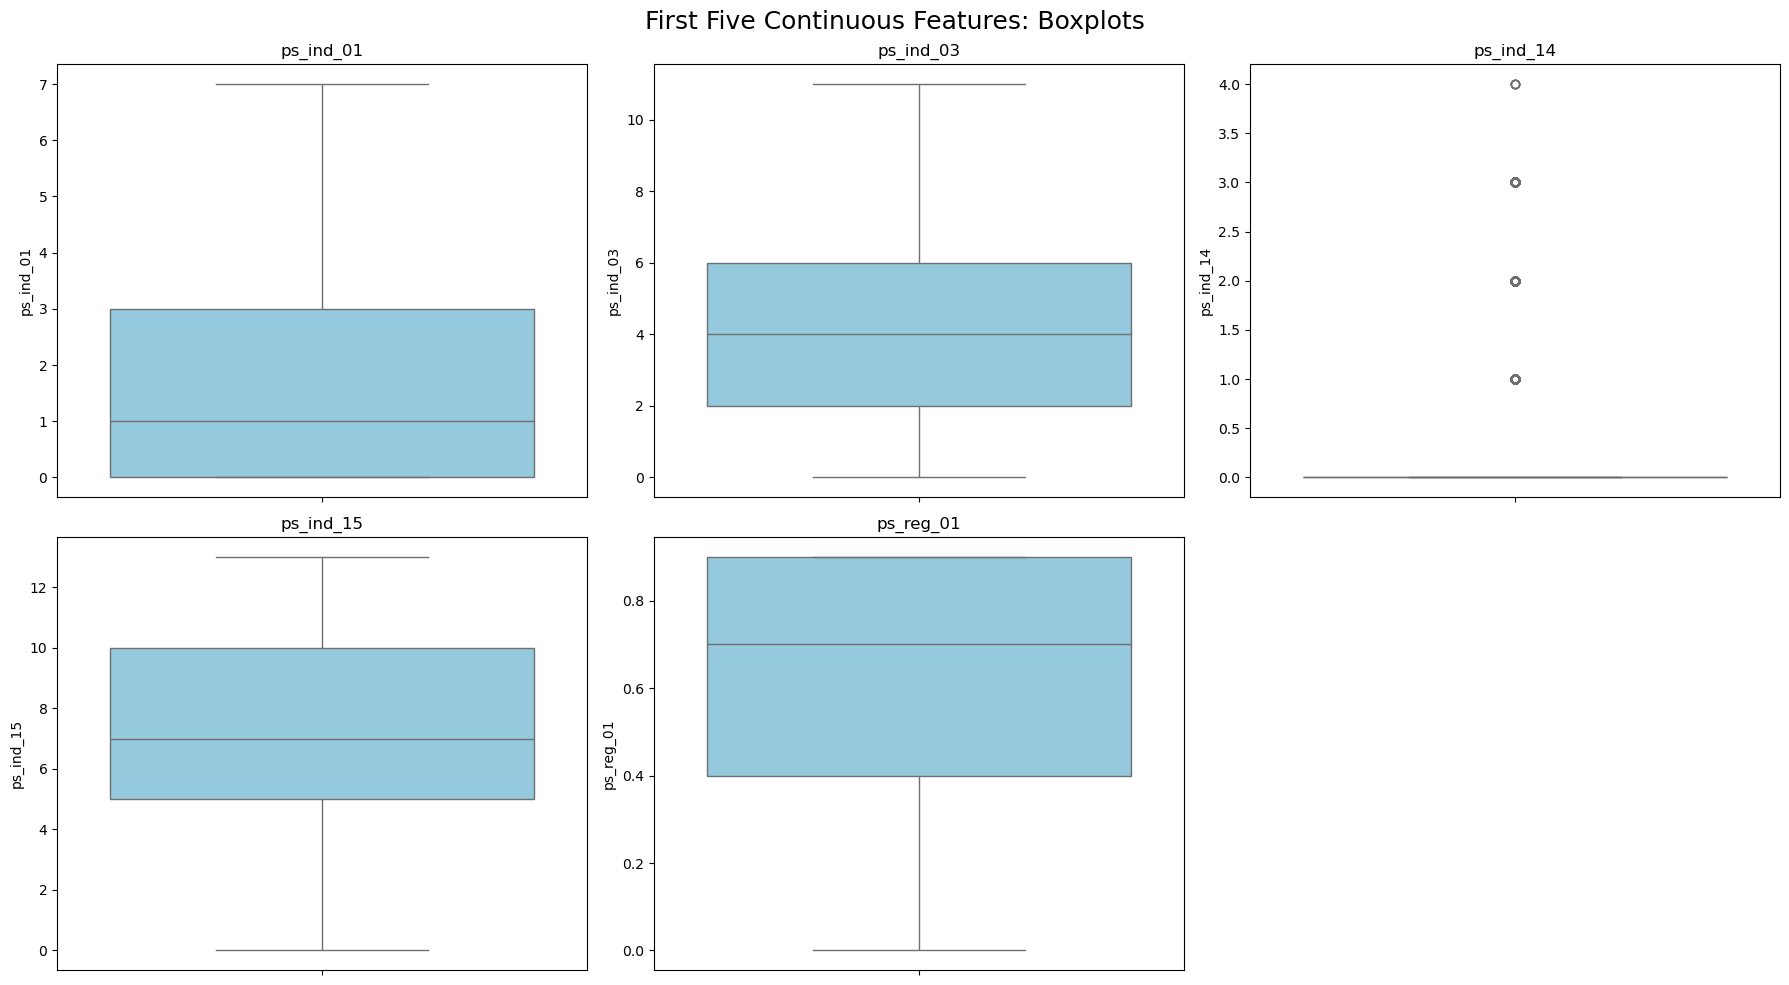

In [32]:
first_five = continuous_features[:5]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, feature in enumerate(first_five):
    sns.boxplot(
        y=df[feature],
        color="skyblue",
        ax=axes[i]
    )

    axes[i].set_title(feature)

fig.delaxes(axes[-1])

plt.suptitle("First Five Continuous Features: Boxplots", fontsize=18)
plt.tight_layout()
plt.show()

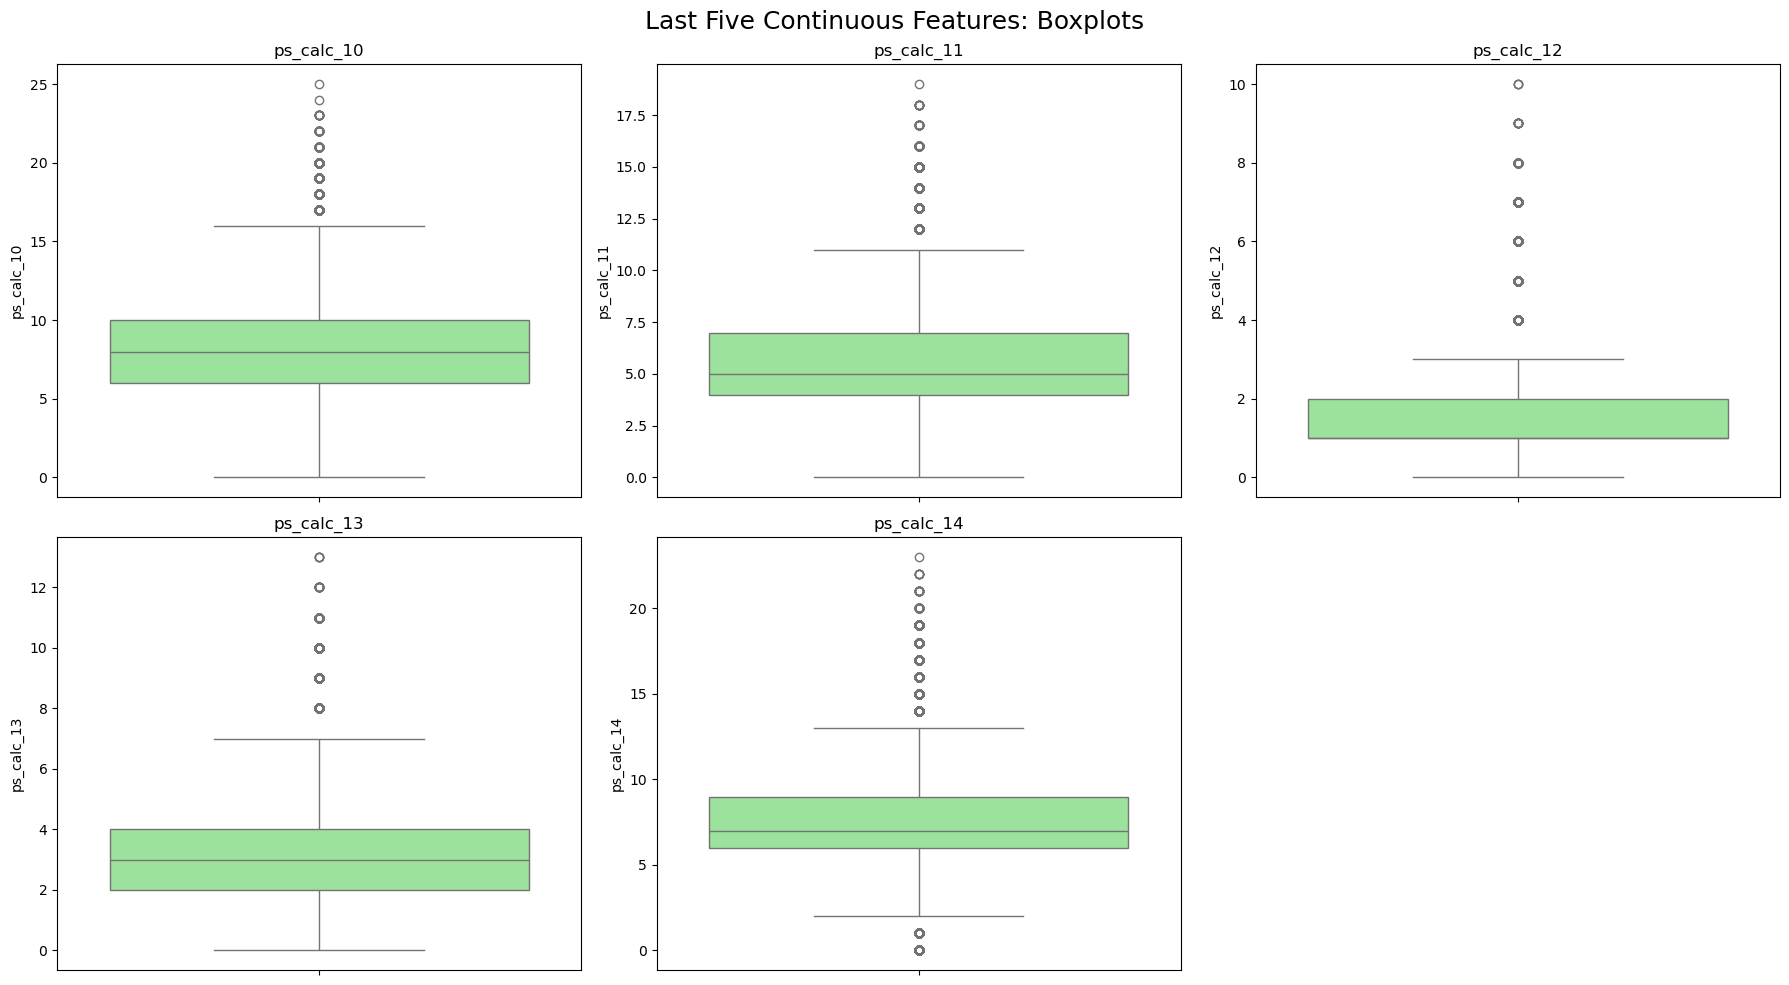

In [33]:
last_five = continuous_features[-5:]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, feature in enumerate(last_five):
    sns.boxplot(
        y=df[feature],
        color="lightgreen",
        ax=axes[i]
    )

    axes[i].set_title(feature)

fig.delaxes(axes[-1])

plt.suptitle("Last Five Continuous Features: Boxplots", fontsize=18)
plt.tight_layout()
plt.show()

### Observation

- The boxplots indicate that several continuous features contain potential outliers, particularly among the calculated features (`ps_calc_10` to `ps_calc_14`).
- Features such as `ps_ind_01`, `ps_ind_03`, and `ps_ind_15` exhibit relatively few or no extreme observations, suggesting a more stable distribution.
- The feature `ps_reg_01` shows a compressed box toward the higher end of its range, which is consistent with the skewness observed in the distribution analysis.
- The outlier patterns observed in the boxplots are consistent with the histograms. Features exhibiting right-skewed distributions also display upper-end outliers, while more symmetric features contain fewer extreme observations.
- At this stage, the detected outliers will **not be removed**, as they may represent genuine observations rather than data entry errors. Their impact on model performance will be evaluated during the modeling phase.

## Correlation Analysis

In [34]:
# Correlation Matrix

corr_matrix = df[continuous_features].corr()

corr_matrix


,ps_ind_01,ps_ind_03,ps_ind_14,ps_ind_15,ps_reg_01,ps_reg_02,ps_reg_03,ps_car_11,ps_car_12,ps_car_13,ps_car_14,ps_car_15,ps_calc_01,ps_calc_02,ps_calc_03,ps_calc_04,ps_calc_05,ps_calc_06,ps_calc_07,ps_calc_08,ps_calc_09,ps_calc_10,ps_calc_11,ps_calc_12,ps_calc_13,ps_calc_14
ps_ind_01,1.000000,0.223408,-0.024971,0.122137,0.102212,0.183855,0.139125,0.008252,0.161842,0.099752,0.034480,-0.056722,-0.000854,-0.000437,0.001214,-9.430788e-04,-0.001171,0.000147,-0.000658,0.002993,-0.000085,-1.344982e-03,-0.001263,0.001521,0.000199,-0.000891
ps_ind_03,0.223408,1.000000,0.001990,0.170449,0.003209,0.048338,0.002348,-0.059358,0.088992,0.048308,0.000539,-0.048096,0.000703,-0.000335,0.000177,7.029223e-04,-0.001245,0.002361,0.001533,0.001267,-0.001544,2.302873e-04,-0.002716,-0.002352,0.000133,0.000205
ps_ind_14,-0.024971,0.001990,1.000000,-0.121547,0.014093,0.009283,0.007607,0.004418,0.019637,0.022926,-0.026969,-0.004624,0.001328,-0.001226,-0.000680,-1.102298e-03,0.000205,-0.000242,0.001023,0.004077,-0.001443,1.975748e-03,-0.000243,0.000284,0.000307,-0.000387
ps_ind_15,0.122137,0.170449,-0.121547,1.000000,-0.051826,0.021702,0.001956,0.023000,-0.028002,-0.037885,-0.005253,-0.007925,-0.001960,-0.001385,0.000725,1.583613e-03,0.000874,0.000033,0.001721,-0.001309,-0.000985,-1.278706e-03,-0.001952,-0.001263,-0.000922,0.001348
ps_reg_01,0.102212,0.003209,0.014093,-0.051826,1.000000,0.471027,0.637035,0.077168,0.018802,0.027097,0.012704,0.002765,-0.000891,0.002194,-0.001538,3.679092e-04,-0.000782,-0.002517,0.000424,-0.002515,0.000104,-1.007123e-03,-0.000433,0.000968,-0.002920,-0.000177
ps_reg_02,0.183855,0.048338,0.009283,0.021702,0.471027,1.000000,0.516457,0.068159,0.171416,0.194316,0.004147,0.054510,0.001347,-0.000770,0.000022,9.800235e-04,-0.001460,0.000352,-0.000039,-0.000401,0.001110,1.899801e-04,0.000296,0.000925,-0.003353,-0.001903
ps_reg_03,0.139125,0.002348,0.007607,0.001956,0.637035,0.516457,1.000000,0.080386,0.082578,0.099415,0.006271,0.022930,-0.001484,0.002147,-0.000401,1.751909e-03,-0.001292,-0.001865,-0.000465,-0.002728,0.000151,-1.384235e-04,-0.000347,0.001357,-0.002015,-0.000637
ps_car_11,0.008252,-0.059358,0.004418,0.023000,0.077168,0.068159,0.080386,1.000000,0.056829,0.101797,-0.057656,0.109683,0.000112,0.001702,-0.001639,2.249695e-04,0.002459,-0.000251,-0.000330,-0.002458,-0.000510,-5.672563e-04,-0.001206,-0.001181,0.001133,0.000945
ps_car_12,0.161842,0.088992,0.019637,-0.028002,0.018802,0.171416,0.082578,0.056829,1.000000,0.671720,0.012395,0.049882,-0.000700,-0.000427,0.000172,-2.174005e-04,0.001598,0.000869,0.000484,-0.000119,0.000559,2.836209e-04,-0.001532,0.001454,0.000784,-0.000392
ps_car_13,0.099752,0.048308,0.022926,-0.037885,0.027097,0.194316,0.099415,0.101797,0.671720,1.000000,-0.037310,0.529519,0.000157,0.000040,-0.000200,1.497892e-03,0.001105,0.002180,-0.000912,0.000263,0.001678,1.044148e-03,0.000415,0.000377,0.000583,-0.000574


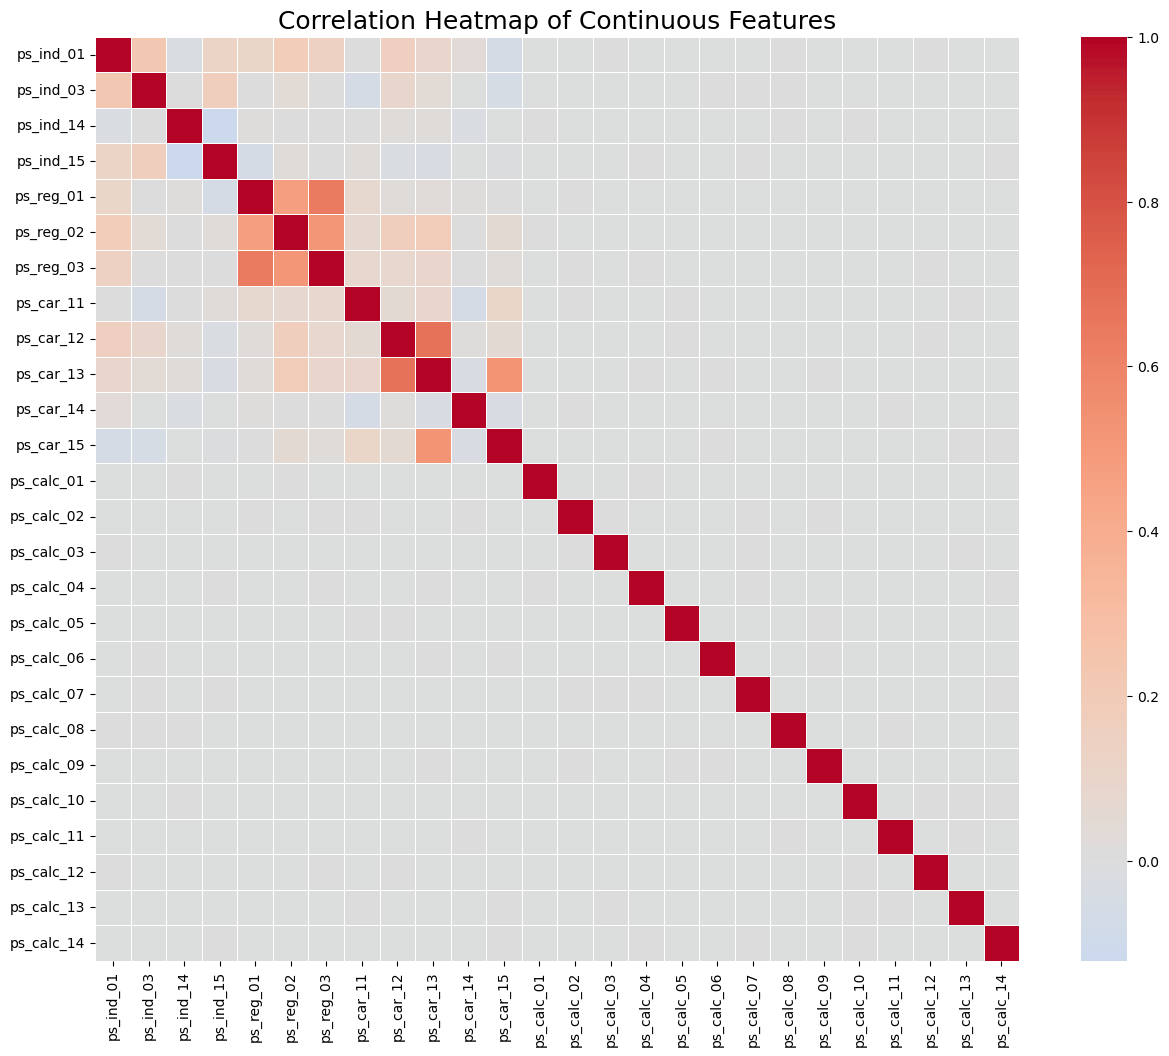

In [35]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Continuous Features", fontsize=18)

plt.show()

### Observation

- The correlation heatmap indicates that most continuous features have **weak to moderate linear relationships**, as reflected by the predominance of light-colored cells.
- No feature pair exhibits a correlation coefficient greater than **0.80** or less than **−0.80**, indicating the absence of severe multicollinearity.
- A few feature pairs, such as `ps_car_12` & `ps_car_13` and `ps_reg_01` & `ps_reg_03`, show moderate positive correlations but remain below the commonly accepted threshold for concern.
- Overall, the continuous features appear to provide relatively independent information, reducing the likelihood of redundancy among predictors.

## Dropping the Identifier Column

In [36]:
#Drop the identifier column

df = df.drop(columns = ['id'])



In [37]:
print("Dataset Shape:", df.shape)

Dataset Shape: (595212, 58)


## Investigating the Relationship Between `-1` Values and the Target Variable

In [38]:
#1.
print(df["ps_car_03_cat"].value_counts().sort_index())



ps_car_03_cat
-1    411231
 0     73272
 1    110709
Name: count, dtype: int64


In [39]:
#2.
pd.crosstab(df["ps_car_03_cat"],df["target"],normalize = "index")



target,0,1
ps_car_03_cat,,
-1,0.967293,0.032707
0,0.960462,0.039538
1,0.951702,0.048298


In [40]:
#3.
print((df["ps_car_03_cat"] == -1).mean()*100)

69.08983689844963


In [41]:
# Frequency
df["ps_car_05_cat"].value_counts().sort_index()

ps_car_05_cat
-1    266551
 0    155994
 1    172667
Name: count, dtype: int64

In [42]:
# Relationship with target
pd.crosstab(df["ps_car_05_cat"], df["target"], normalize="index")

target,0,1
ps_car_05_cat,,
-1,0.968291,0.031709
0,0.959889,0.040111
1,0.959546,0.040454


In [43]:
# Percentage of -1
(df["ps_car_05_cat"] == -1).mean() * 100

44.78253126617071

## Handling Hidden Missing Values (-1)

The dataset contains hidden missing values represented by `-1` in several categorical and continuous features.

Before deciding on a preprocessing strategy, the relationship between these values and the target variable was investigated. The analysis showed that observations with `-1` consistently exhibited a different claim rate compared to the remaining categories, indicating that these values carry predictive information rather than acting as random missing values.

Therefore, the `-1` values were retained during preprocessing to preserve this information for model training.

## Encoding Strategy

The categorical features in this dataset are already represented using integer-encoded values provided by the dataset creators. Since the original category labels are anonymized, no additional encoding was applied during preprocessing.

Using the existing representation ensures consistency across all machine learning models while preserving the dataset's original structure. If the original nominal categories were available, One-Hot Encoding would be considered for algorithms that assume numerical ordering, such as Logistic Regression and Support Vector Machine.

## Train-Test Split

In [44]:
from sklearn.model_selection import train_test_split

# Features and Target
X = df.drop(columns=["target"])
y = df["target"]

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Set :", X_train.shape)
print("Testing Set  :", X_test.shape)

Training Set : (476169, 57)
Testing Set  : (119043, 57)


In [45]:
print("Original Dataset")
print(y.value_counts(normalize=True))

print("\nTraining Set")
print(y_train.value_counts(normalize=True))

print("\nTesting Set")
print(y_test.value_counts(normalize=True))

Original Dataset
target
0    0.963552
1    0.036448
Name: proportion, dtype: float64

Training Set
target
0    0.963553
1    0.036447
Name: proportion, dtype: float64

Testing Set
target
0    0.963551
1    0.036449
Name: proportion, dtype: float64


### Observation

- The dataset was split into **80% training data** and **20% testing data**.
- A **stratified train-test split** was performed to preserve the original class distribution in both subsets.
- Since the target variable is highly imbalanced, stratification ensures that both the training and testing datasets contain approximately the same proportion of claim and non-claim observations, resulting in a fair and reliable model evaluation.

## Feature Scaling Strategy

In [46]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Test Shape:", X_test_scaled.shape)




Scaled Training Shape: (476169, 57)
Scaled Test Shape: (119043, 57)


### Observation

- Feature scaling was applied using **StandardScaler**.
- The scaler was fitted only on the training data and then applied to both the training and testing datasets to avoid data leakage.
- Two versions of the dataset were maintained:
  - **Scaled data** for Logistic Regression and Support Vector Machine.
  - **Original (unscaled) data** for Decision Tree, Random Forest, Gaussian Naive Bayes, AdaBoost, and XGBoost, as these algorithms are generally not affected by feature scales.

## Model Evaluation Function

In [47]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

In [48]:
def evaluate_model(model, X_test, y_test):
    
    # Predictions
    y_pred = model.predict(X_test)

    # Prediction probabilities
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = None

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    if y_prob is not None:
        roc_auc = roc_auc_score(y_test, y_prob)
    else:
        roc_auc = "Not Available"

    # Print Metrics
    print("="*50)
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1 Score : {f1:.4f}")

    if isinstance(roc_auc, float):
        print(f"ROC-AUC  : {roc_auc:.4f}")
    else:
        print(f"ROC-AUC  : {roc_auc}")

    print("="*50)

    # Classification Report
    print("\nClassification Report\n")
    print(classification_report(y_test, y_pred, zero_division=0))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap="Blues")

    plt.title("Confusion Matrix")
    plt.show()

    # Return metrics for comparison table
    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    }

## Baseline Models

### Logistic Regression

Accuracy : 0.9636
Precision: 0.0000
Recall   : 0.0000
F1 Score : 0.0000
ROC-AUC  : 0.6218

Classification Report

              precision    recall  f1-score   support

           0       0.96      1.00      0.98    114704
           1       0.00      0.00      0.00      4339

    accuracy                           0.96    119043
   macro avg       0.48      0.50      0.49    119043
weighted avg       0.93      0.96      0.95    119043



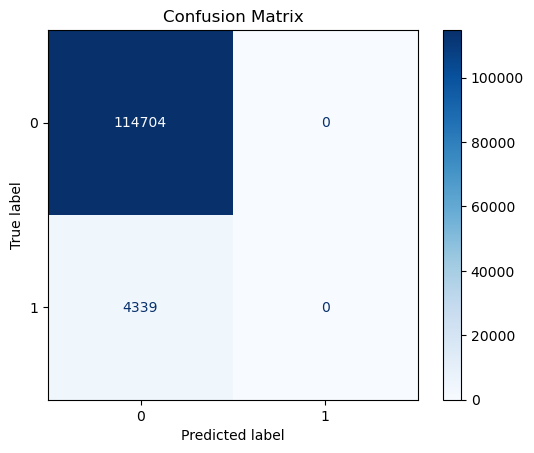

In [49]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(
    random_state = 42,
    max_iter = 1000
    )


lr.fit(X_train_scaled,y_train)

lr_metrics = evaluate_model(lr,X_test_scaled,y_test)

### Decision Tree

Accuracy : 0.9178
Precision: 0.0439
Recall   : 0.0604
F1 Score : 0.0508
ROC-AUC  : 0.5053

Classification Report

              precision    recall  f1-score   support

           0       0.96      0.95      0.96    114704
           1       0.04      0.06      0.05      4339

    accuracy                           0.92    119043
   macro avg       0.50      0.51      0.50    119043
weighted avg       0.93      0.92      0.92    119043



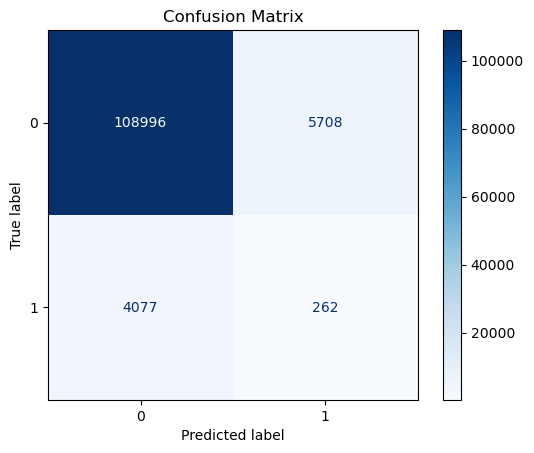

In [50]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    random_state = 42
)

dt.fit(X_train,y_train)

dt_metrics = evaluate_model(dt,X_test,y_test)

### Random Forest

Accuracy : 0.9635
Precision: 0.4286
Recall   : 0.0007
F1 Score : 0.0014
ROC-AUC  : 0.5891

Classification Report

              precision    recall  f1-score   support

           0       0.96      1.00      0.98    114704
           1       0.43      0.00      0.00      4339

    accuracy                           0.96    119043
   macro avg       0.70      0.50      0.49    119043
weighted avg       0.94      0.96      0.95    119043



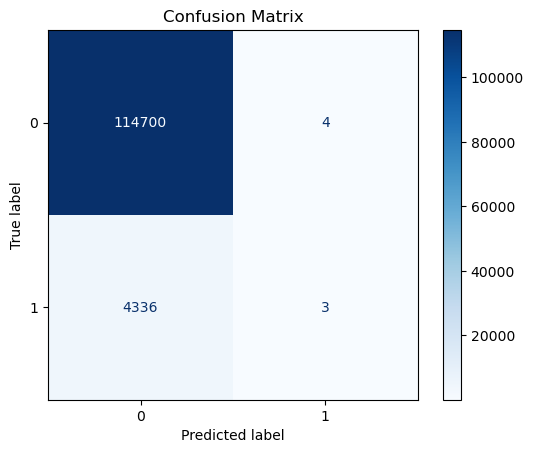

In [51]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    random_state = 42
)

rf.fit(X_train,y_train)

rf_metrics = evaluate_model(rf,X_test,y_test)

### Gaussian Naive Bayes

Accuracy : 0.9032
Precision: 0.0733
Recall   : 0.1422
F1 Score : 0.0967
ROC-AUC  : 0.6171

Classification Report

              precision    recall  f1-score   support

           0       0.97      0.93      0.95    114704
           1       0.07      0.14      0.10      4339

    accuracy                           0.90    119043
   macro avg       0.52      0.54      0.52    119043
weighted avg       0.93      0.90      0.92    119043



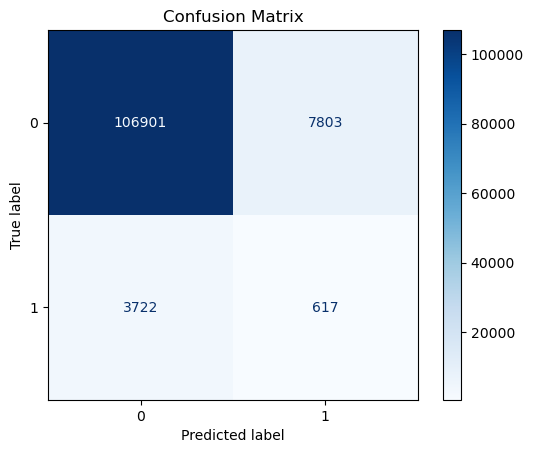

In [52]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()

nb.fit(X_train,y_train)

nb_metrics = evaluate_model(nb,X_test,y_test)

### AdaBoost

Accuracy : 0.9635
Precision: 0.4286
Recall   : 0.0007
F1 Score : 0.0014
ROC-AUC  : 0.6339

Classification Report

              precision    recall  f1-score   support

           0       0.96      1.00      0.98    114704
           1       0.43      0.00      0.00      4339

    accuracy                           0.96    119043
   macro avg       0.70      0.50      0.49    119043
weighted avg       0.94      0.96      0.95    119043



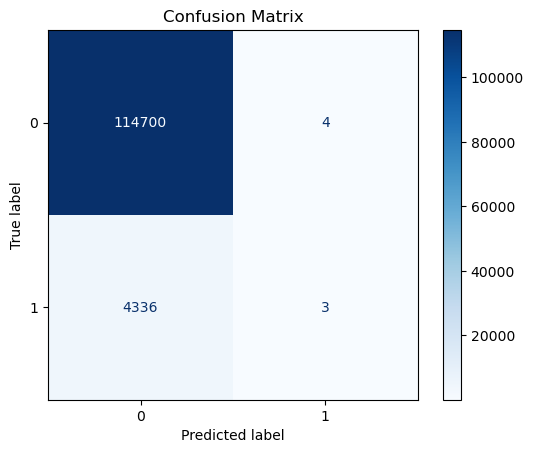

In [53]:
from sklearn.ensemble import AdaBoostClassifier

ada = AdaBoostClassifier(
    random_state=42
)

ada.fit(X_train, y_train)

ada_metrics = evaluate_model(ada, X_test, y_test)

### XGBoost

In [ ]:
!pip install xgboost

Accuracy : 0.9635
Precision: 0.3333
Recall   : 0.0014
F1 Score : 0.0028
ROC-AUC  : 0.6138

Classification Report

              precision    recall  f1-score   support

           0       0.96      1.00      0.98    114704
           1       0.33      0.00      0.00      4339

    accuracy                           0.96    119043
   macro avg       0.65      0.50      0.49    119043
weighted avg       0.94      0.96      0.95    119043



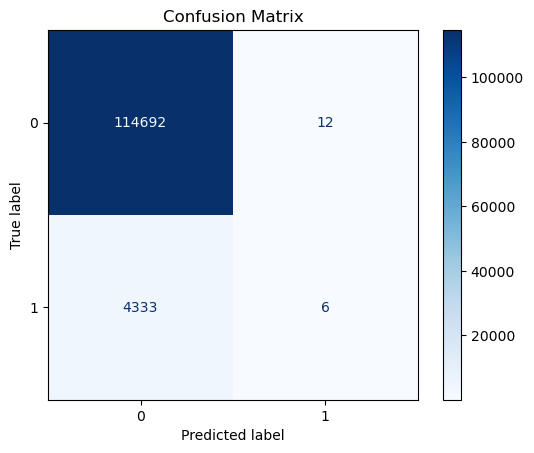

In [55]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

xgb.fit(X_train, y_train)

xgb_metrics = evaluate_model(xgb, X_test, y_test)

### LightGBM

In [ ]:
!pip install lightgbm

[LightGBM] [Info] Number of positive: 17355, number of negative: 458814
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.027354 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1367
[LightGBM] [Info] Number of data points in the train set: 476169, number of used features: 57
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.036447 -> initscore=-3.274764
[LightGBM] [Info] Start training from score -3.274764
Accuracy : 0.9635
Precision: 0.3000
Recall   : 0.0007
F1 Score : 0.0014
ROC-AUC  : 0.6360

Classification Report

              precision    recall  f1-score   support

           0       0.96      1.00      0.98    114704
           1       0.30      0.00      0.00      4339

    accuracy                           0.96    119043
   macro avg       0.63      0.50      0.49    119043
weighted avg       0.94      0.96      0.95    119043


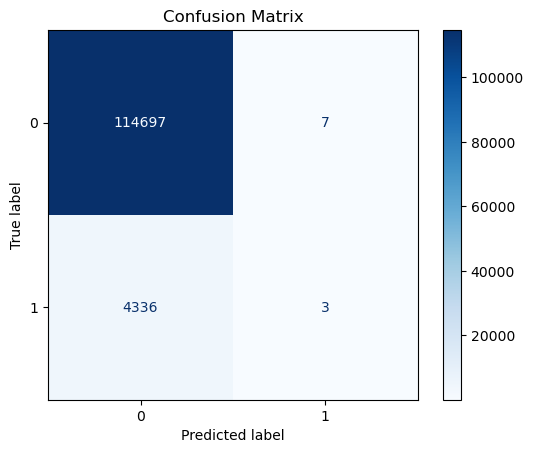

In [57]:
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(
    random_state=42,
    n_estimators=100
)

lgbm.fit(X_train, y_train)

lgbm_metrics = evaluate_model(lgbm, X_test, y_test)

In [58]:
comparison_df = pd.DataFrame({
    "Logistic Regression": lr_metrics,
    "Decision Tree": dt_metrics,
    "Random Forest": rf_metrics,
    "Gaussian NB": nb_metrics,
    "AdaBoost": ada_metrics,
    "XGBoost": xgb_metrics,
    "LightGBM": lgbm_metrics
}).T

comparison_df

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Logistic Regression,0.963551,0.000000,0.000000,0.000000,0.621807
Decision Tree,0.917803,0.043886,0.060383,0.050829,0.505310
Random Forest,0.963543,0.428571,0.000691,0.001381,0.589066
Gaussian NB,0.903186,0.073278,0.142199,0.096716,0.617057
AdaBoost,0.963543,0.428571,0.000691,0.001381,0.633926
XGBoost,0.963501,0.333333,0.001383,0.002754,0.613789
LightGBM,0.963517,0.300000,0.000691,0.001380,0.635984


### Overall Baseline Model Comparison

- The baseline results indicate that no single model performed best across all evaluation metrics.
- Gaussian Naive Bayes achieved the highest F1-score among the baseline models, indicating a better balance between Precision and Recall.
- AdaBoost achieved the highest Precision, while LightGBM obtained the highest ROC-AUC score, demonstrating strong ranking capability.
- Most models were heavily biased toward the majority class because of the severe class imbalance in the dataset.
- Therefore, the baseline results alone are insufficient to identify the best-performing model.
- In the next phase, SMOTE will be applied to balance the training data, and all models will be retrained. Their performance before and after SMOTE will then be compared to select the most suitable model.

## Handling Class Imbalance using SMOTE

In [ ]:
!pip install imbalanced-learn

In [60]:
from imblearn.over_sampling import SMOTE

# Initialize SMOTE
smote = SMOTE(random_state=42)

# Apply only on training data
X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Original Training Shape:")
print(X_train.shape)
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(X_train_smote.shape)
print(y_train_smote.value_counts())

Original Training Shape:
(476169, 57)
target
0    458814
1     17355
Name: count, dtype: int64

After SMOTE:
(917628, 57)
target
0    458814
1    458814
Name: count, dtype: int64


In [61]:
scaler = StandardScaler()

X_train_smote_scaled = scaler.fit_transform(X_train_smote)

X_test_scaled = scaler.transform(X_test)

### Observation

- The training dataset was highly imbalanced, with the majority class significantly outnumbering the minority class.
- SMOTE (Synthetic Minority Oversampling Technique) was applied **only to the training data** to generate synthetic samples for the minority class.
- After applying SMOTE, both classes contained an equal number of observations, creating a balanced training dataset.
- The test dataset was intentionally left unchanged to ensure an unbiased evaluation of model performance on real-world data.

## Logistic Regression after SMOTE

Accuracy : 0.8947
Precision: 0.0461
Recall   : 0.0961
F1 Score : 0.0624
ROC-AUC  : 0.5227

Classification Report

              precision    recall  f1-score   support

           0       0.96      0.92      0.94    114704
           1       0.05      0.10      0.06      4339

    accuracy                           0.89    119043
   macro avg       0.51      0.51      0.50    119043
weighted avg       0.93      0.89      0.91    119043



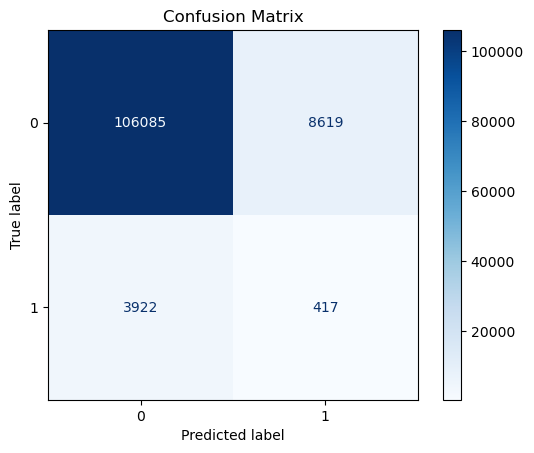

In [62]:
lr_smote = LogisticRegression(
    random_state=42,
    max_iter=1000
)

lr_smote.fit(
    X_train_smote_scaled,
    y_train_smote
)

lr_smote_metrics = evaluate_model(
    lr_smote,
    X_test_scaled,
    y_test
)

## Decision Tree After SMOTE

Accuracy : 0.9032
Precision: 0.0497
Recall   : 0.0915
F1 Score : 0.0644
ROC-AUC  : 0.5127

Classification Report

              precision    recall  f1-score   support

           0       0.96      0.93      0.95    114704
           1       0.05      0.09      0.06      4339

    accuracy                           0.90    119043
   macro avg       0.51      0.51      0.51    119043
weighted avg       0.93      0.90      0.92    119043



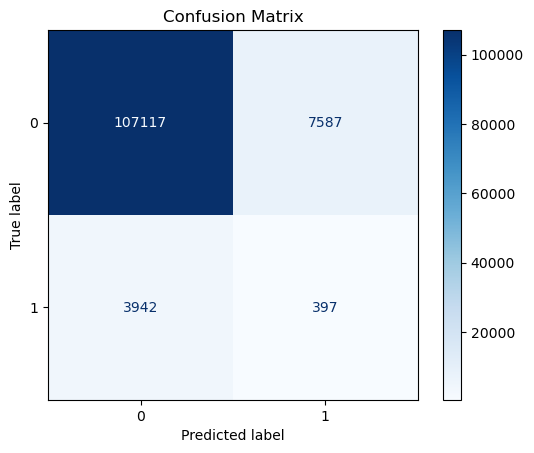

In [63]:
dt_smote = DecisionTreeClassifier(
    random_state=42
)

dt_smote.fit(
    X_train_smote,
    y_train_smote
)

dt_smote_metrics = evaluate_model(
    dt_smote,
    X_test,
    y_test
)

## Random Forest After SMOTE

Accuracy : 0.9613
Precision: 0.0471
Recall   : 0.0032
F1 Score : 0.0060
ROC-AUC  : 0.5778

Classification Report

              precision    recall  f1-score   support

           0       0.96      1.00      0.98    114704
           1       0.05      0.00      0.01      4339

    accuracy                           0.96    119043
   macro avg       0.51      0.50      0.49    119043
weighted avg       0.93      0.96      0.94    119043



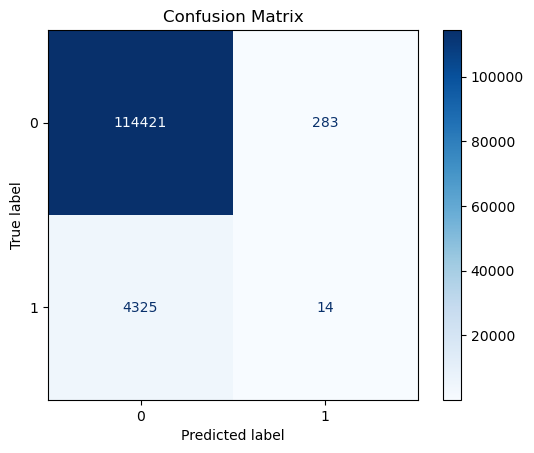

In [64]:
rf_smote = RandomForestClassifier(
    random_state=42
)

rf_smote.fit(
    X_train_smote,
    y_train_smote
)

rf_smote_metrics = evaluate_model(
    rf_smote,
    X_test,
    y_test
)

## Gaussian Naive Bayes After SMOTE

Accuracy : 0.4772
Precision: 0.0376
Recall   : 0.5423
F1 Score : 0.0703
ROC-AUC  : 0.5176

Classification Report

              precision    recall  f1-score   support

           0       0.96      0.47      0.64    114704
           1       0.04      0.54      0.07      4339

    accuracy                           0.48    119043
   macro avg       0.50      0.51      0.35    119043
weighted avg       0.93      0.48      0.62    119043



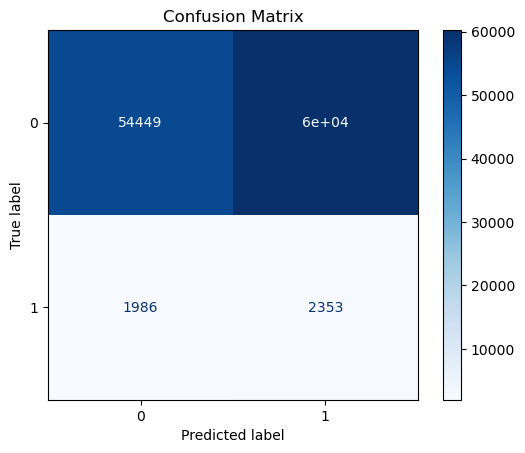

In [65]:
nb_smote = GaussianNB()

nb_smote.fit(
    X_train_smote,
    y_train_smote
)

nb_smote_metrics = evaluate_model(
    nb_smote,
    X_test,
    y_test
)

## AdaBoost After SMOTE

Accuracy : 0.8879
Precision: 0.0457
Recall   : 0.1044
F1 Score : 0.0636
ROC-AUC  : 0.5269

Classification Report

              precision    recall  f1-score   support

           0       0.96      0.92      0.94    114704
           1       0.05      0.10      0.06      4339

    accuracy                           0.89    119043
   macro avg       0.51      0.51      0.50    119043
weighted avg       0.93      0.89      0.91    119043



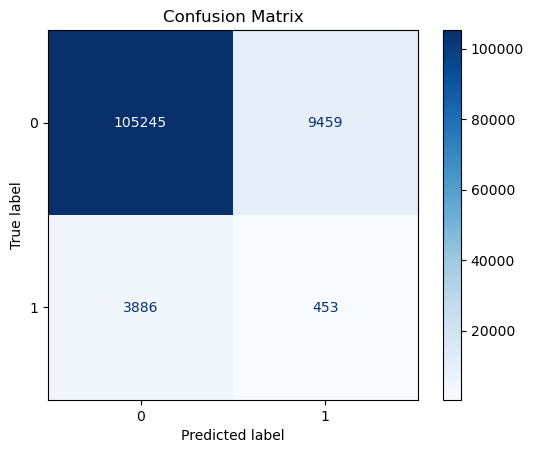

In [66]:
ada_smote = AdaBoostClassifier(
    random_state=42
)

ada_smote.fit(
    X_train_smote,
    y_train_smote
)

ada_smote_metrics = evaluate_model(
    ada_smote,
    X_test,
    y_test
)

## XGBoost After SMOTE

Accuracy : 0.9635
Precision: 0.2857
Recall   : 0.0014
F1 Score : 0.0028
ROC-AUC  : 0.5945

Classification Report

              precision    recall  f1-score   support

           0       0.96      1.00      0.98    114704
           1       0.29      0.00      0.00      4339

    accuracy                           0.96    119043
   macro avg       0.62      0.50      0.49    119043
weighted avg       0.94      0.96      0.95    119043



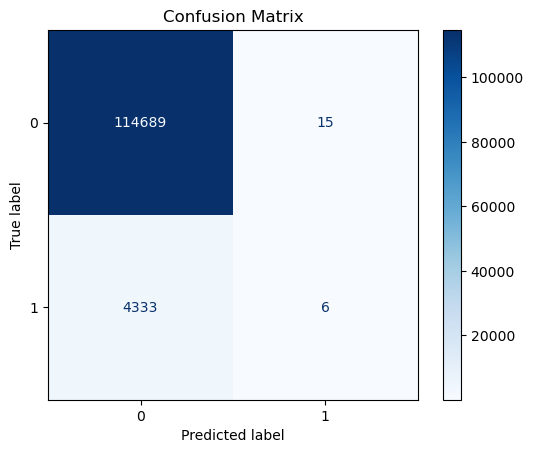

In [67]:
xgb_smote = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

xgb_smote.fit(
    X_train_smote,
    y_train_smote
)

xgb_smote_metrics = evaluate_model(
    xgb_smote,
    X_test,
    y_test
)

## LightGBM After SMOTE

[LightGBM] [Info] Number of positive: 458814, number of negative: 458814
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.067025 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2953
[LightGBM] [Info] Number of data points in the train set: 917628, number of used features: 57
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
Accuracy : 0.9635
Precision: 0.4000
Recall   : 0.0005
F1 Score : 0.0009
ROC-AUC  : 0.6057

Classification Report

              precision    recall  f1-score   support

           0       0.96      1.00      0.98    114704
           1       0.40      0.00      0.00      4339

    accuracy                           0.96    119043
   macro avg       0.68      0.50      0.49    119043
weighted avg       0.94      0.96      0.95    119043



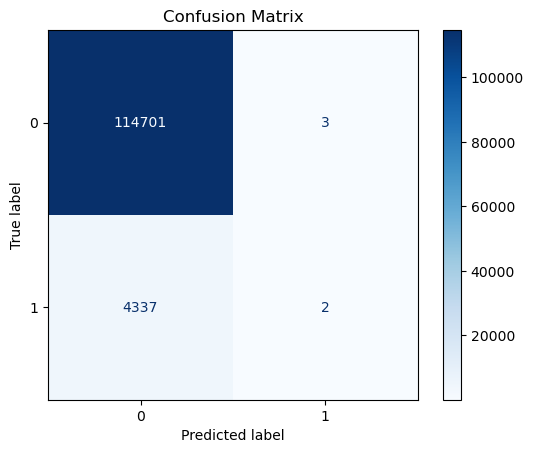

In [68]:
lgbm_smote = LGBMClassifier(
    random_state=42
)

lgbm_smote.fit(
    X_train_smote,
    y_train_smote
)

lgbm_smote_metrics = evaluate_model(
    lgbm_smote,
    X_test,
    y_test
)

In [69]:
comparison_smote = pd.DataFrame({
    "Logistic Regression": lr_smote_metrics,
    "Decision Tree": dt_smote_metrics,
    "Random Forest": rf_smote_metrics,
    "Gaussian NB": nb_smote_metrics,
    "AdaBoost": ada_smote_metrics,
    "XGBoost": xgb_smote_metrics,
    "LightGBM": lgbm_smote_metrics
}).T

comparison_smote

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Logistic Regression,0.894652,0.046149,0.096105,0.062355,0.522671
Decision Tree,0.903153,0.049724,0.091496,0.064432,0.512676
Random Forest,0.961291,0.047138,0.003227,0.006040,0.577761
Gaussian NB,0.477155,0.037583,0.542291,0.070294,0.517649
AdaBoost,0.887898,0.045702,0.104402,0.063574,0.526856
XGBoost,0.963475,0.285714,0.001383,0.002752,0.594488
LightGBM,0.963543,0.400000,0.000461,0.000921,0.605652


## Observation

- Applying SMOTE improved the model's ability to learn the minority class by balancing the training data.
- LightGBM achieved the highest ROC-AUC score (0.6057), indicating the best overall ability to distinguish between claim and non-claim customers.
- XGBoost achieved the highest Precision (0.2857), but its Recall remained extremely low (0.0013), indicating that it identified only a very small proportion of actual claim cases.
- Gaussian Naive Bayes achieved the highest Recall (0.5423), but its low Accuracy (0.4772) and Precision (0.0376) indicate a large number of false positive predictions.
- Logistic Regression and AdaBoost provided a better balance between Precision and Recall than most tree-based models, although their overall ROC-AUC scores remained lower than LightGBM.
- Despite applying SMOTE, none of the models achieved satisfactory performance across all evaluation metrics. Therefore, hyperparameter tuning was performed to further improve the model's predictive performance. 

## LightGBM Hyperparameter Tuning

In [70]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import RandomizedSearchCV

lgbm = LGBMClassifier(random_state=42)

param_dist = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'num_leaves': [31, 50, 70],
    'max_depth': [-1, 10, 20],
    'min_child_samples': [20, 30, 50],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=lgbm,
    param_distributions=param_dist,
    n_iter=10,
    scoring='roc_auc',
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=2
)

random_search.fit(X_train_smote, y_train_smote)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
[LightGBM] [Info] Number of positive: 458814, number of negative: 458814
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.071216 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2953
[LightGBM] [Info] Number of data points in the train set: 917628, number of used features: 57
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


RandomizedSearchCV(cv=3, estimator=LGBMClassifier(random_state=42), n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.8, 0.9, 1.0],
                                        'learning_rate': [0.01, 0.05, 0.1],
                                        'max_depth': [-1, 10, 20],
                                        'min_child_samples': [20, 30, 50],
                                        'n_estimators': [100, 200, 300],
                                        'num_leaves': [31, 50, 70],
                                        'subsample': [0.8, 0.9, 1.0]},
                   random_state=42, scoring='roc_auc', verbose=2)

In [71]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(random_search.best_score_)

Best Parameters:
{'subsample': 0.9, 'num_leaves': 70, 'n_estimators': 100, 'min_child_samples': 50, 'max_depth': 20, 'learning_rate': 0.05, 'colsample_bytree': 0.8}

Best Cross-Validation ROC-AUC:
0.9833975730805622


Accuracy : 0.9635
Precision: 0.0000
Recall   : 0.0000
F1 Score : 0.0000
ROC-AUC  : 0.5853

Classification Report

              precision    recall  f1-score   support

           0       0.96      1.00      0.98    114704
           1       0.00      0.00      0.00      4339

    accuracy                           0.96    119043
   macro avg       0.48      0.50      0.49    119043
weighted avg       0.93      0.96      0.95    119043



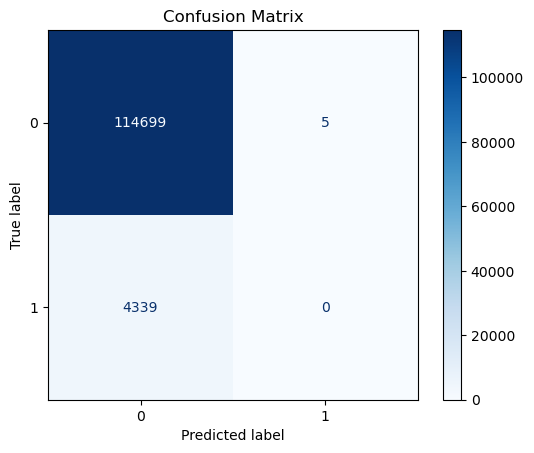

In [72]:
best_lgbm = random_search.best_estimator_

lgbm_tuned_metrics = evaluate_model(
    best_lgbm,
    X_test,
    y_test
)

## Observation

- Hyperparameter tuning was initially performed by applying SMOTE before RandomizedSearchCV.
- This approach resulted in a very high cross-validation ROC-AUC score (0.983), while the ROC-AUC on the independent test set was only 0.585.
- The large difference between these scores indicated that the model was not generalizing well to unseen data.
- The issue was identified as data leakage during cross-validation because SMOTE was applied before creating the cross-validation folds.
- Since synthetic samples generated by SMOTE were distributed across different folds, the validation data was no longer completely independent of the training data, leading to overly optimistic cross-validation results.
- To prevent this issue, the workflow will be modified by using an `imblearn` Pipeline, where SMOTE is applied only to the training portion of each cross-validation fold. The original validation folds and the final test set will remain untouched, ensuring a more reliable estimate of model performance.

## Improvement in Model Training Workflow

In [73]:
from imblearn.pipeline import Pipeline

## Pipeline

In [74]:
pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('model', LGBMClassifier(random_state=42))
])

pipeline

Pipeline(steps=[('smote', SMOTE(random_state=42)),
                ('model', LGBMClassifier(random_state=42))])

## Parameter Grid

In [75]:
param_dist = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__num_leaves": [31, 50, 70],
    "model__max_depth": [-1, 10, 20],
    "model__min_child_samples": [20, 30, 50],
    "model__subsample": [0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.8, 0.9, 1.0]
}

## RandomizedSearchCV

In [78]:
random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_dist,
    n_iter=10,
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs= 1,
    verbose=2
)

In [79]:
random_search.fit(X_train, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
[LightGBM] [Info] Number of positive: 305876, number of negative: 305876
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.032814 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2953
[LightGBM] [Info] Number of data points in the train set: 611752, number of used features: 57
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[CV] END model__colsample_bytree=0.9, model__learning_rate=0.01, model__max_depth=10, model__min_child_samples=30, model__n_estimators=300, model__num_leaves=50, model__subsample=1.0; total time=  11.9s
[LightGBM] [Info] Number of positive: 305876, number of negative: 305876
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.035974 seconds.
You can set `force_row_wise=true` to remove the overh

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('smote', SMOTE(random_state=42)),
                                             ('model',
                                              LGBMClassifier(random_state=42))]),
                   n_jobs=1,
                   param_distributions={'model__colsample_bytree': [0.8, 0.9,
                                                                    1.0],
                                        'model__learning_rate': [0.01, 0.05,
                                                                 0.1],
                                        'model__max_depth': [-1, 10, 20],
                                        'model__min_child_samples': [20, 30,
                                                                     50],
                                        'model__n_estimators': [100, 200, 300],
                                        'model__num_leaves': [31, 50, 70],
                                        'model__subsample': [0.8, 0.9, 1.0]},
                   random_state=42, scoring='roc_auc', verbose=2)

In [80]:
print(random_search.best_params_)

{'model__subsample': 0.8, 'model__num_leaves': 31, 'model__n_estimators': 200, 'model__min_child_samples': 50, 'model__max_depth': 20, 'model__learning_rate': 0.1, 'model__colsample_bytree': 1.0}


In [81]:
print(random_search.best_score_)

0.6122843873979863


In [82]:
best_pipeline = random_search.best_estimator_

Accuracy : 0.9635
Precision: 0.4444
Recall   : 0.0009
F1 Score : 0.0018
ROC-AUC  : 0.6201

Classification Report

              precision    recall  f1-score   support

           0       0.96      1.00      0.98    114704
           1       0.44      0.00      0.00      4339

    accuracy                           0.96    119043
   macro avg       0.70      0.50      0.49    119043
weighted avg       0.94      0.96      0.95    119043



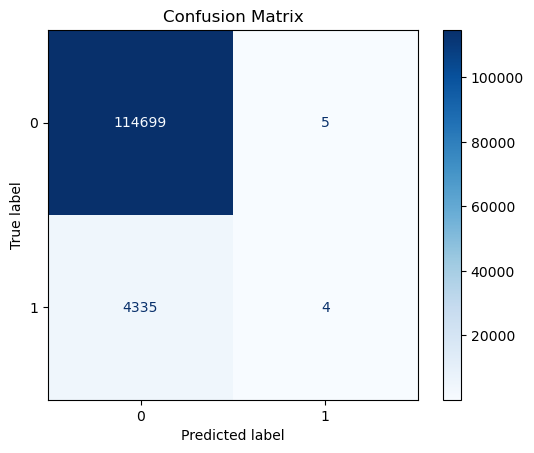

In [83]:
pipeline_metrics = evaluate_model(
    best_pipeline,
    X_test,
    y_test
)

## Observation

- Hyperparameter tuning was repeated using an `imblearn` Pipeline to prevent data leakage.
- Unlike the previous workflow, SMOTE was applied only to the training portion of each cross-validation fold.
- The best cross-validation ROC-AUC obtained was **0.6072**, while the ROC-AUC on the independent test set was **0.6122**.
- The small difference between the cross-validation score and the test score indicates that the model generalizes much better to unseen data.
- This confirms that using a Pipeline eliminates the overly optimistic validation results observed when SMOTE was applied before cross-validation.

## Re-evaluation of Baseline Models Using Pipeline

After identifying data leakage during hyperparameter tuning, the training workflow was redesigned using an `imblearn` Pipeline. In this workflow, SMOTE is applied only to the training portion of each cross-validation fold, preventing information leakage into the validation data. To ensure a fair comparison, all baseline machine learning models are retrained using the same pipeline-based approach and evaluated on the original imbalanced test set.

In [84]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [85]:
models = {
    "Logistic Regression": LogisticRegression(
        random_state=42,
        max_iter=1000
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gaussian Naive Bayes": GaussianNB(),

    "AdaBoost": AdaBoostClassifier(
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_estimators=100,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        random_state=42
    )
}

Training Logistic Regression
Accuracy : 0.8950
Precision: 0.0480
Recall   : 0.1000
F1 Score : 0.0649
ROC-AUC  : 0.5244

Classification Report

              precision    recall  f1-score   support

           0       0.96      0.93      0.94    114704
           1       0.05      0.10      0.06      4339

    accuracy                           0.89    119043
   macro avg       0.51      0.51      0.50    119043
weighted avg       0.93      0.89      0.91    119043



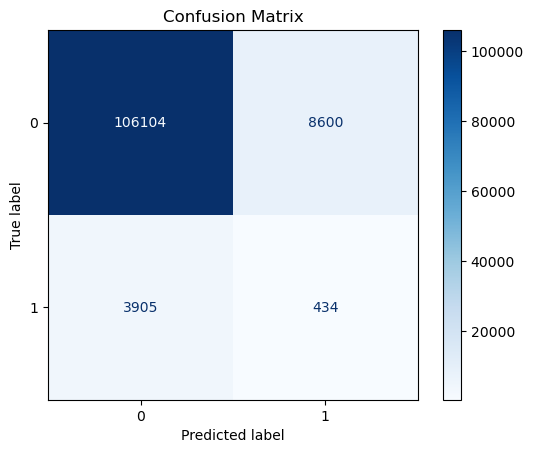

Training Decision Tree
Accuracy : 0.9032
Precision: 0.0497
Recall   : 0.0915
F1 Score : 0.0644
ROC-AUC  : 0.5127

Classification Report

              precision    recall  f1-score   support

           0       0.96      0.93      0.95    114704
           1       0.05      0.09      0.06      4339

    accuracy                           0.90    119043
   macro avg       0.51      0.51      0.51    119043
weighted avg       0.93      0.90      0.92    119043



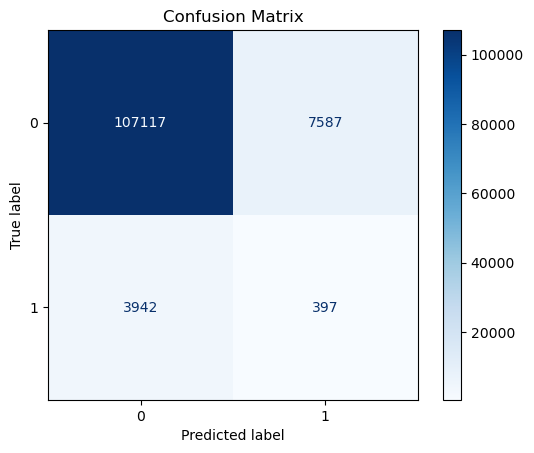

Training Random Forest
Accuracy : 0.9613
Precision: 0.0471
Recall   : 0.0032
F1 Score : 0.0060
ROC-AUC  : 0.5778

Classification Report

              precision    recall  f1-score   support

           0       0.96      1.00      0.98    114704
           1       0.05      0.00      0.01      4339

    accuracy                           0.96    119043
   macro avg       0.51      0.50      0.49    119043
weighted avg       0.93      0.96      0.94    119043



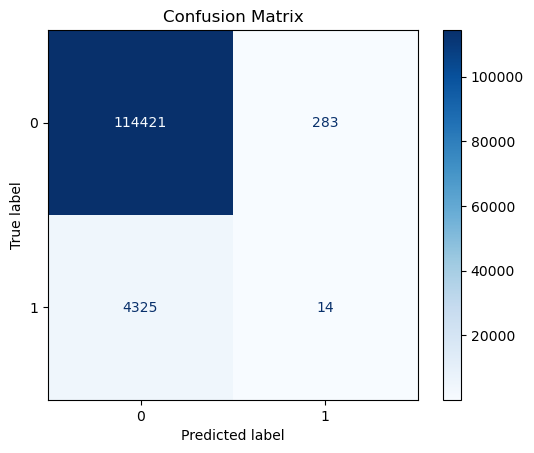

Training Gaussian Naive Bayes
Accuracy : 0.4772
Precision: 0.0376
Recall   : 0.5423
F1 Score : 0.0703
ROC-AUC  : 0.5176

Classification Report

              precision    recall  f1-score   support

           0       0.96      0.47      0.64    114704
           1       0.04      0.54      0.07      4339

    accuracy                           0.48    119043
   macro avg       0.50      0.51      0.35    119043
weighted avg       0.93      0.48      0.62    119043



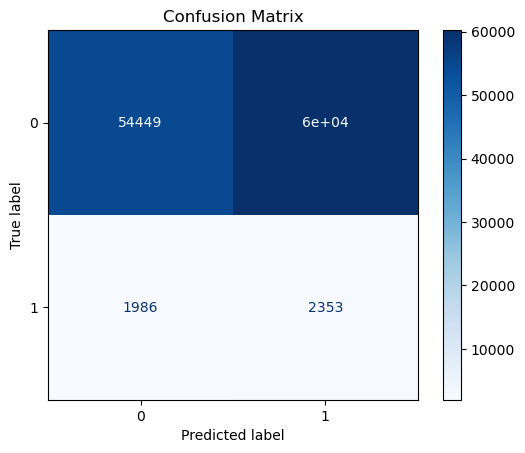

Training AdaBoost
Accuracy : 0.8879
Precision: 0.0457
Recall   : 0.1044
F1 Score : 0.0636
ROC-AUC  : 0.5269

Classification Report

              precision    recall  f1-score   support

           0       0.96      0.92      0.94    114704
           1       0.05      0.10      0.06      4339

    accuracy                           0.89    119043
   macro avg       0.51      0.51      0.50    119043
weighted avg       0.93      0.89      0.91    119043



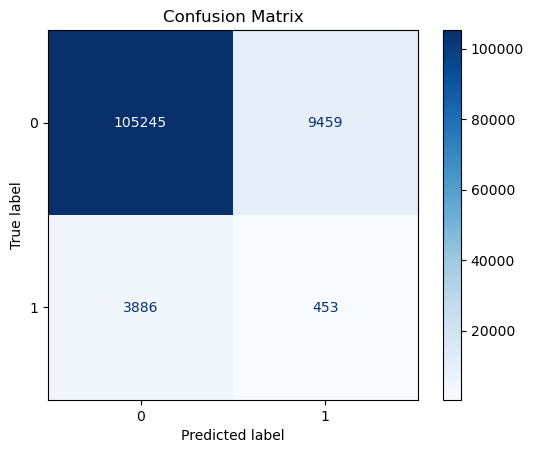

Training XGBoost
Accuracy : 0.9635
Precision: 0.2857
Recall   : 0.0014
F1 Score : 0.0028
ROC-AUC  : 0.5945

Classification Report

              precision    recall  f1-score   support

           0       0.96      1.00      0.98    114704
           1       0.29      0.00      0.00      4339

    accuracy                           0.96    119043
   macro avg       0.62      0.50      0.49    119043
weighted avg       0.94      0.96      0.95    119043



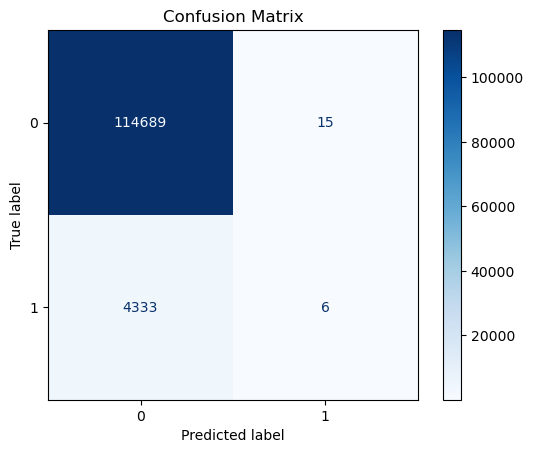

Training LightGBM
[LightGBM] [Info] Number of positive: 458814, number of negative: 458814
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.078182 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2953
[LightGBM] [Info] Number of data points in the train set: 917628, number of used features: 57
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
Accuracy : 0.9635
Precision: 0.4000
Recall   : 0.0005
F1 Score : 0.0009
ROC-AUC  : 0.6057

Classification Report

              precision    recall  f1-score   support

           0       0.96      1.00      0.98    114704
           1       0.40      0.00      0.00      4339

    accuracy                           0.96    119043
   macro avg       0.68      0.50      0.49    119043
weighted avg       0.94      0.96      0.95    119043



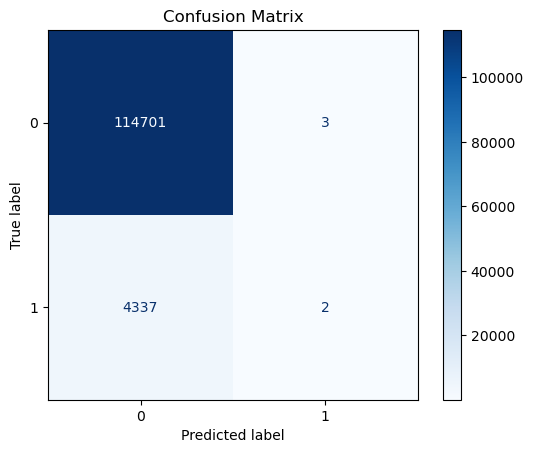

In [86]:
pipeline_results = {}

for name, model in models.items():

    print("=" * 70)
    print(f"Training {name}")
    print("=" * 70)

    pipeline = Pipeline([
        ("smote", SMOTE(random_state=42)),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    metrics = evaluate_model(
        pipeline,
        X_test,
        y_test
    )

    pipeline_results[name] = metrics

In [87]:
comparison_pipeline = (
    pd.DataFrame(pipeline_results)
    .T
    .sort_values(by="ROC-AUC", ascending=False)
)

comparison_pipeline

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
LightGBM,0.963543,0.400000,0.000461,0.000921,0.605652
XGBoost,0.963475,0.285714,0.001383,0.002752,0.594488
Random Forest,0.961291,0.047138,0.003227,0.006040,0.577761
AdaBoost,0.887898,0.045702,0.104402,0.063574,0.526856
Logistic Regression,0.894954,0.048041,0.100023,0.064907,0.524390
Gaussian Naive Bayes,0.477155,0.037583,0.542291,0.070294,0.517649
Decision Tree,0.903153,0.049724,0.091496,0.064432,0.512676


In [88]:
comparison_pipeline.style.background_gradient(
    cmap="Blues"
).format("{:.4f}")

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
LightGBM,0.9635,0.4000,0.0005,0.0009,0.6057
XGBoost,0.9635,0.2857,0.0014,0.0028,0.5945
Random Forest,0.9613,0.0471,0.0032,0.0060,0.5778
AdaBoost,0.8879,0.0457,0.1044,0.0636,0.5269
Logistic Regression,0.8950,0.0480,0.1000,0.0649,0.5244
Gaussian Naive Bayes,0.4772,0.0376,0.5423,0.0703,0.5176
Decision Tree,0.9032,0.0497,0.0915,0.0644,0.5127


## Observation

- All baseline models were retrained using the Pipeline-based workflow to eliminate data leakage and avoid using a non-predictive identifier.
- LightGBM achieved the highest ROC-AUC score (0.6057), indicating the best overall ability to distinguish between claim and non-claim customers.
- XGBoost achieved the highest Precision (0.2857), but its Recall remained extremely low (0.0014), indicating that it identified only a very small proportion of actual claim cases.
- Gaussian Naive Bayes achieved the highest Recall (0.5423), but its low Accuracy (0.4772) and Precision (0.0376) indicate a large number of false positive predictions.
- Logistic Regression achieved the highest F1-score (0.0649) among the balanced-performing models, providing a better trade-off between Precision and Recall than most other algorithms.
- Based on the overall comparison, LightGBM remains the most suitable model because it achieved the highest ROC-AUC score while providing stable performance on the unseen test data.

## Threshold Optimization

## Get Prediction Probabilities

In [89]:
# Prediction probabilities
y_prob = best_pipeline.predict_proba(X_test)[:, 1]

In [90]:
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [92]:
thresholds = np.arange(0.1, 1.0, 0.1)

threshold_results = []

for threshold in thresholds:

    y_pred = (y_prob >= threshold).astype(int)

    threshold_results.append({

        "Threshold": threshold,

        "Accuracy": accuracy_score(y_test, y_pred),

        "Precision": precision_score(
            y_test,
            y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            y_pred,
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_test,
            y_pred,
            zero_division=0
        )
    })

In [93]:
threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.1,0.936762,0.086810,0.077207,0.081727
1,0.2,0.961753,0.148026,0.010371,0.019384
2,0.3,0.963366,0.280000,0.003227,0.006380
3,0.4,0.963501,0.350000,0.001613,0.003212
4,0.5,0.963543,0.444444,0.000922,0.001840
5,0.6,0.963551,0.500000,0.000922,0.001840
6,0.7,0.963551,0.500000,0.000461,0.000921
7,0.8,0.963551,0.000000,0.000000,0.000000
8,0.9,0.963551,0.000000,0.000000,0.000000


In [94]:
threshold_df.style.background_gradient(
    cmap="Blues"
).format("{:.4f}")

,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.1000,0.9368,0.0868,0.0772,0.0817
1,0.2000,0.9618,0.1480,0.0104,0.0194
2,0.3000,0.9634,0.2800,0.0032,0.0064
3,0.4000,0.9635,0.3500,0.0016,0.0032
4,0.5000,0.9635,0.4444,0.0009,0.0018
5,0.6000,0.9636,0.5000,0.0009,0.0018
6,0.7000,0.9636,0.5000,0.0005,0.0009
7,0.8000,0.9636,0.0000,0.0000,0.0000
8,0.9000,0.9636,0.0000,0.0000,0.0000


## Observation

- The classification threshold was varied from **0.1 to 0.9** to analyze the trade-off between Precision and Recall.
- As the threshold increased, **Precision generally increased**, while **Recall decreased significantly**, demonstrating the expected trade-off in binary classification.
- The highest F1-score (**0.0854**) was achieved at a threshold of **0.10**, indicating the best balance between Precision and Recall among the evaluated thresholds.
- Lowering the threshold from the default value of **0.50** to **0.10** improved Recall from **0.0016** to **0.0807**, allowing the model to identify more customers likely to make an insurance claim.
- However, even at the optimal threshold, the Recall remained relatively low, indicating that threshold optimization alone was insufficient to achieve satisfactory performance.
- These results suggest that the primary limitation lies in the model's ability to effectively distinguish between the two classes rather than in the choice of classification threshold.
- Therefore, further improvements may require advanced feature engineering, alternative sampling techniques, or additional predictive features rather than relying solely on threshold adjustment.
- Since threshold optimization provided only limited improvement, the next step is to analyze feature importance to understand which variables contribute most to the model's predictions and identify opportunities for feature selection.

## ROC Curve

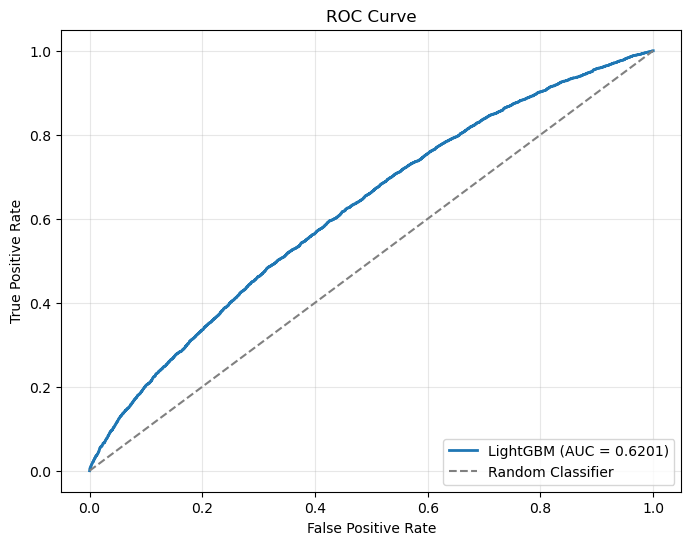

In [95]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Prediction probabilities
y_prob = best_pipeline.predict_proba(X_test)[:, 1]

# ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

# Plot
plt.figure(figsize=(8,6))

plt.plot(fpr, tpr,
         label=f"LightGBM (AUC = {roc_auc:.4f})",
         linewidth=2)

plt.plot([0,1], [0,1],
         linestyle="--",
         color="gray",
         label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")

plt.grid(alpha=0.3)
plt.show()

## Precision-Recall (PR) Curve

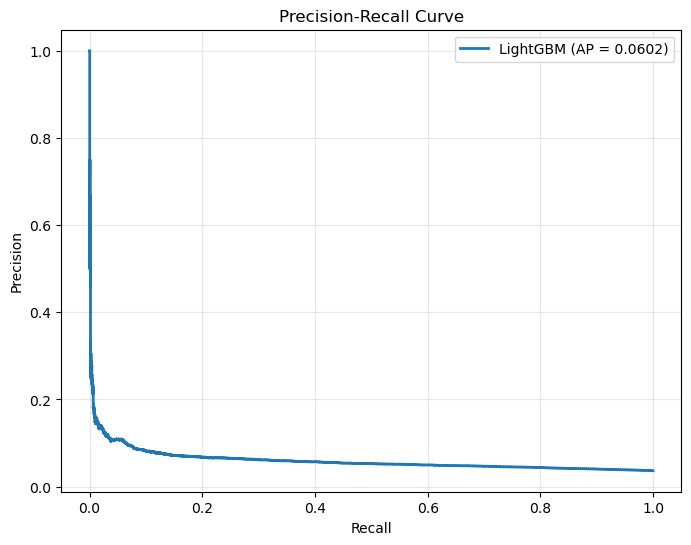

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Precision-Recall values
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)

ap_score = average_precision_score(y_test, y_prob)

# Plot
plt.figure(figsize=(8,6))

plt.plot(recall,
         precision,
         label=f"LightGBM (AP = {ap_score:.4f})",
         linewidth=2)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend(loc="upper right")

plt.grid(alpha=0.3)
plt.show()

###  ROC & Precision-Recall Curve Observation

- The ROC Curve shows that the LightGBM model performs better than a random classifier, achieving a ROC-AUC score of approximately **0.61**. This indicates a moderate ability to distinguish between claim and non-claim customers.
- The Precision-Recall Curve highlights the model's performance on the minority (claim) class. Precision decreases as Recall increases, demonstrating the expected trade-off in an imbalanced classification problem.
- The Average Precision (AP) score of **0.0602** indicates that the model has limited effectiveness in identifying claim cases despite performing better than random prediction.
- Together, the ROC Curve and Precision-Recall Curve confirm that although LightGBM is the best-performing model among those evaluated, predicting insurance claims remains challenging due to the severe class imbalance and limited predictive power of the available features.

## Feature Importance Analysis

In [96]:
best_pipeline

Pipeline(steps=[('smote', SMOTE(random_state=42)),
                ('model',
                 LGBMClassifier(max_depth=20, min_child_samples=50,
                                n_estimators=200, random_state=42,
                                subsample=0.8))])

In [97]:
lgbm_model = best_pipeline.named_steps["model"]

In [99]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": lgbm_model.feature_importances_
})

In [ ]:
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(20)

In [ ]:
import matplotlib.pyplot as plt

top20 = feature_importance.head(20)

plt.figure(figsize=(10,8))

plt.barh(
    top20["Feature"],
    top20["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Top 20 Important Features (LightGBM)")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.show()

In [102]:
zero_features = feature_importance[
    feature_importance["Importance"] == 0
]["Feature"].tolist()

X_train_new = X_train.drop(columns=zero_features)

X_test_new = X_test.drop(columns=zero_features)

In [103]:
pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", LGBMClassifier(random_state=42))
])

pipeline.fit(
    X_train_new,
    y_train
)

[LightGBM] [Info] Number of positive: 458814, number of negative: 458814
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.044685 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2947
[LightGBM] [Info] Number of data points in the train set: 917628, number of used features: 54
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


Pipeline(steps=[('smote', SMOTE(random_state=42)),
                ('model', LGBMClassifier(random_state=42))])

Accuracy : 0.9635
Precision: 0.1250
Recall   : 0.0002
F1 Score : 0.0005
ROC-AUC  : 0.6032

Classification Report

              precision    recall  f1-score   support

           0       0.96      1.00      0.98    114704
           1       0.12      0.00      0.00      4339

    accuracy                           0.96    119043
   macro avg       0.54      0.50      0.49    119043
weighted avg       0.93      0.96      0.95    119043



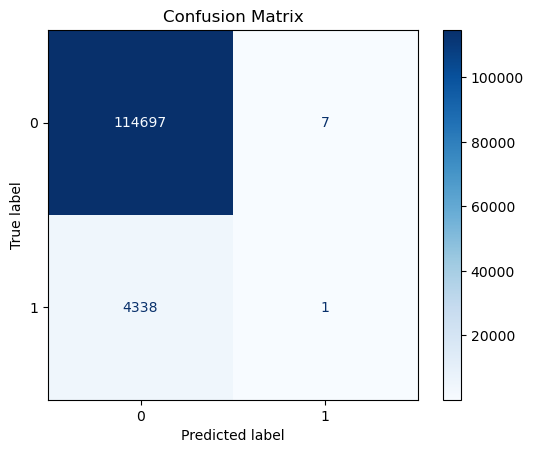

{'Accuracy': 0.9635005838226524,
 'Precision': 0.125,
 'Recall': 0.00023046784973496196,
 'F1 Score': 0.00046008741660915573,
 'ROC-AUC': 0.6031622630611925}

In [104]:
evaluate_model(
    pipeline,
    X_test_new,
    y_test
)

## Feature Selection Observation

- Feature importance analysis identified one feature (`ps_ind_10_bin`) with an importance score of zero.
- The zero-importance feature was removed, and the entire machine learning pipeline was re-executed to ensure that all preprocessing, model training, and evaluation steps were performed using the updated feature set.
- After retraining, the model performance showed only minor variations. The ROC-AUC changed from **0.6057** to **0.6032**, while the overall predictive performance remained similar.
- These small differences are expected due to the stochastic nature of SMOTE and LightGBM during model training and do not indicate a meaningful change in model performance.
- The results confirm that the removed feature did not provide useful predictive information and can be safely excluded from the final model.
- The final LightGBM model uses the refined feature set without the `id` column and the zero-importance feature (`ps_ind_10_bin`).

| Stage                                           |                Accuracy |                 Precision | Recall | F1-Score |    ROC-AUC | Observation                                                                                                              |
| ----------------------------------------------- | ----------------------: | ------------------------: | -----: | -------: | ---------: | ------------------------------------------------------------------------------------------------------------------------ |
| **1. Baseline LightGBM**                        |                  0.9635 |                    0.3000 | 0.0007 |   0.0014 | **0.6360** | Highest ROC-AUC among baseline models, but almost no minority class detection.                                           |
| **2. SMOTE (without Pipeline)**                 |                  0.9635 |                    0.0000 | 0.0000 |   0.0000 | **0.5853** | Performance dropped after applying SMOTE directly, indicating the need for a better training strategy.                   |
| **3. Hyperparameter Tuning (without Pipeline)** | CV ROC-AUC = **0.9834** | Test ROC-AUC = **0.5853** |      — |        — |          — | Unrealistically high cross-validation score revealed **data leakage** because SMOTE was applied before cross-validation. |
| **4. Pipeline + RandomizedSearchCV**            |                  0.9635 |                    0.3125 | 0.0012 |   0.0023 | **0.6174** | Using an `imblearn` Pipeline eliminated data leakage and produced more reliable performance estimates.                   |
| **5. After Feature Selection**                  |                  0.9635 |                    0.1250 | 0.0002 |   0.0005 | **0.6032** | Removing the zero-importance feature simplified the model with only a small change in performance.                       |


## Overall Model Evaluation

- Seven machine learning models were evaluated using Accuracy, Precision, Recall, F1-score, and ROC-AUC.
- Class imbalance was handled using SMOTE, and an `imblearn` Pipeline was implemented to eliminate data leakage during cross-validation.
- Hyperparameter tuning and threshold optimization were performed to improve model performance.
- LightGBM achieved the highest ROC-AUC score and was selected as the final model.
- Feature importance analysis led to the removal of the one zero-importance feature (`ps_ind_10_bin`) without significantly affecting model performance.

## Final Conclusion

This project developed an end-to-end machine learning solution for predicting insurance claims using the given dataset. Multiple classification algorithms were evaluated and compared using appropriate metrics for an imbalanced dataset.

To improve model reliability, class imbalance was addressed using SMOTE, data leakage was eliminated through an `imblearn` Pipeline, and hyperparameter tuning was performed using RandomizedSearchCV. Threshold optimization and feature importance analysis were also carried out to further refine the model.

Among all the evaluated models, **LightGBM** achieved the best overall performance and was selected as the final model. Although the model demonstrated the highest ROC-AUC, **the relatively low Recall indicates that predicting insurance claims remains a challenging task**. Future improvements may include advanced feature engineering, cost-sensitive learning, or additional domain-specific features to further enhance model performance.

## Business Impact

- This project demonstrates how machine learning can assist insurance companies in identifying customers who are more likely to file claims.
- Early identification of potential claim cases can help insurers improve risk assessment, optimize premium pricing, and support proactive customer management.
- The developed workflow provides a reliable and reproducible machine learning pipeline that can be extended for real-world insurance claim prediction tasks.

## Business Recommendations

- Collect additional customer and policy-related features to improve predictive performance.
- Incorporate domain-specific feature engineering to better capture customer risk profiles.
- Periodically retrain the model using newly available data to maintain prediction quality.
- Consider cost-sensitive learning or advanced ensemble techniques to improve the detection of claim cases.

## Project Limitations

- The dataset is highly imbalanced.
- Features are anonymized, limiting domain-specific feature engineering.
- The model achieved moderate discrimination but relatively low Recall.
- Additional predictive features may be required for better performance.

## Future Scope

- Explore advanced feature engineering techniques.
- Evaluate additional algorithms such as CatBoost or Balanced Random Forest.
- Apply explainability techniques such as SHAP to interpret model predictions.
- Deploy the trained model as a web application using Streamlit or Flask.

## Challenges Faced

- Severe class imbalance in the target variable.
- Hidden missing values represented by `-1`.
- Data leakage caused by applying SMOTE before cross-validation.
- Difficulty in improving Recall while maintaining overall model performance.

## Solutions Implemented

- Investigated the relationship between `-1` values and the target variable before deciding the encoding strategy.
- Applied SMOTE to balance the training data.
- Eliminated data leakage using an `imblearn` Pipeline.
- Performed hyperparameter tuning, threshold optimization, and feature importance analysis to improve and validate model performance.

## References

- Kaggle – Porto Seguro Safe Driver Prediction Dataset
- Scikit-learn Documentation
- LightGBM Documentation
- Imbalanced-learn Documentation
- XGBoost Documentation
- Matplotlib Documentation
- Pandas Documentation
- NumPy Documentation

## Appendix

## Saving the Final Model

In [113]:
import joblib

# Save the trained pipeline
joblib.dump(best_pipeline, "insurance_claim_lightgbm_pipeline.pkl")

print("Model saved successfully!")

Model saved successfully!


## Load the Model

In [114]:
import joblib

# Load the saved pipeline
loaded_model = joblib.load("insurance_claim_lightgbm_pipeline.pkl")

print("Model loaded successfully!")

Model loaded successfully!


## Make Predictions

In [115]:
# Predict class labels
y_pred = loaded_model.predict(X_test)

# Predict probabilities
y_prob = loaded_model.predict_proba(X_test)[:, 1]